# Does Gemma's base model predict nudge effects? — Claim E demo

**The question.** An instruction-tuned LLM has a *default* algorithm for most coding tasks (asked for a path search,
it writes DFS; asked to find a value in a sorted list, it scans linearly). A small activation "nudge" can sometimes
move it off that default, and on other tasks nothing moves it. The **narrowed-repertoire account** says instruction
tuning narrowed a repertoire that the **base** model still has. If so, the base model's own mix of algorithms should
predict (a) *which* tasks a nudge can move and (b) *where* the moved programs land.

This artifact tests that account on a second model family, `google/gemma-3-4b-it` (instruction-tuned, **it**) against
`google/gemma-3-4b-pt` (its base model, **pt**), on 15 frozen coding tasks. It is a **replication, not a held-out
confirmation**: Gemma's iteration-4 push outcomes were already seen.

| Quantity | Meaning |
|---|---|
| $D_u$ | the it model's default algorithm on task $u$ (modal correct label of a fresh, un-pushed **it twin**, N = 50) |
| $\beta_u$ | the pt model's share of *non-default* catalogue algorithms on the same token ids (its repertoire breadth) |
| $r_u$ | the pt model's runner-up algorithm; $q_\text{base}$ its full landing forecast |
| $E_u$ | share of 16 fresh isotropic directions whose push (blocks 11–22, task-spec positions, prefill only) **escapes** $D_u$ without a pass-rate cost, mean over doses α = 1, 2 |
| landing | the modal correct off-default algorithm among the confirmed escapes |
| transplant | the pt model's task-spec states written into the it model (λ = 1), against matched controls RND / XT / RP |

**Pre-registered tests.** *E-A1*: Spearman ρ(β, E) ≥ 0.5 with permutation p < 0.01. *E-A2*: $r_u$ equals the landing
at a hit rate ≥ 0.7 above chance, and $q_\text{base}$ beats iteration 4's forecasts in log score. *Transplant*: the pt
states move base-diverse tasks to $r_u$ while the controls do not.

**Full-run results** (12,290 programs, 2.16 GPU-hours on one NVIDIA L4, USD 0.39 of LLM judges): **E-A2 PASS**
(5/7 landings are the pt runner-up, exact Poisson-binomial p = 0.025; +1.50 nats per event over iteration 4's
association forecast). **E-A1 INCONCLUSIVE** (ρ = 0.42, one-sided p = 0.060, n = 15). **Transplant:** 2 of 7
base-diverse tasks move (T04 naive → builtin 40/50, R6 linear scan → binary search 39/50), both onto the pt
runner-up; every transplanted program stays valid.

### What this notebook runs
The original `method.py` is a 26-stage driver: GPU generation (both Gemma checkpoints, bf16), a background labeller
(a frozen benchmark harness plus OpenRouter judges), hash-chained pre-registration commits, and a CPU analysis.
Generation and labelling cannot run here (gated weights, a ≥ 16 GB GPU, API keys, about 2.5 hours), so the notebook
loads the stored outputs (`mini_demo_data.json`) and re-runs everything that runs on CPU, with the original code:

1. **the driver** `method.py`, verbatim (the full run sits behind `RUN_FULL_PIPELINE = False`);
2. **the intervention** `src/push.py`, a displacement-targeted block-output edit, checked on a toy residual stream;
3. **the frozen analysis** `src/analysis_E.py` (hash-committed before any generation), verbatim, with its self-test;
4. **E-A1 and E-A2** (`src/final_analysis.py`) on the committed predictor table and the escape table; these
   reproduce the full run's numbers exactly;
5. **the transplant analysis** on 100 stored programs (10 tasks × 5 templates × 2 CRN slots, N = 10 per arm instead of
   the full run's 50);
6. **the figures** of `src/figures.py`, plus the realised activation displacement of the transplanted prompts.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py and every src/ module log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# --- method.py (the pipeline driver), verbatim
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/analysis_E.py, src/final_analysis.py, src/push.py, src/figures.py
import collections
import contextlib
import itertools
import json
import math
import types
from typing import Any, Callable, Iterable, Iterator

import numpy as np
from scipy import stats
import torch

# --- notebook additions: data loading and plots
import http.client
import urllib.request
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-5/experiment-28/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

`mini_demo_data.json` holds:
- **`datasets[0]`**: 100 rows of the `gemma_transplant` dataset. Each row is one program the it model wrote under
  the **transplant** arm T, at CRN slots 0–1 of each template W1–W5, for the 7 base-diverse tasks and the 3
  base-collapsed controls. `output` is `label|pass`. `predict_<arm>_same_slot` is the `label|pass` of the program
  written on the **same CRN slot** (same prompt, same sampling uniforms) by the un-pushed twin and by the three
  controls, so the 100 rows rebuild all five arms. `metadata_code` is the transplanted program, and
  `metadata_realised_disp` is the measured activation displacement it was written under.
- **`metadata`**: the per-unit tables that the CPU analysis reads, namely the hash-committed commit-#1 predictor table,
  the escape table of the push population, the E-A2 events, the transplant λ decision and displacement norms. It
  also holds the values the full run reported, for side-by-side comparison.

In [4]:
t0_notebook = time.time()
data = load_data()
print(data["metadata"]["about"])
print("examples:", len(data["datasets"][0]["examples"]), "from dataset", data["datasets"][0]["dataset"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated subset of the Claim E experiment (Gemma-3-4B pt vs it) for code_demo.ipynb. examples = 100 rows of the gemma_transplant dataset: arm T at CRN slots 0-1 of templates W1-W5 for the 7 S_T and 3 S_C tasks; predict_<arm>_same_slot = label|pass of the CRN-coupled twin/RND/XT/RP program. metadata = the per-unit tables the CPU analysis reads (commit-#1 predictor table, escape table, E-A2 events, plan-noise excess, transplant lambda and norms) and the values the full run reported.
examples: 100 from dataset gemma_transplant


## Configuration

The analysis is cheap, so every parameter can run at the full run's value. The demo starts from the values below.
- `N_PERM` / `N_BOOT`: the E-A1 Monte-Carlo permutation test and the paired task bootstrap against each rival.
- `N_PERM_SENSITIVITY`: permutations for each E-A1 sensitivity row.
- `N_SLOTS_PER_TEMPLATE`: how many stored CRN slots per template enter the transplant analysis. The mini data holds
  2 per template (N = 10 per arm); the full run used 10 (N = 50).
- `PUSH_DEMO_*`: the size of the toy residual stream used to check the push edit (Gemma-3-4B: d = 2560).

In [5]:
# ---- tunable parameters (original values of the full run in the comments)
N_PERM = 200_000                 # E-A1 permutation draws (one-sided Spearman p)            original: 200_000
N_BOOT = 10_000                 # E-A1 paired task-bootstrap draws, beta vs each rival      original: 10_000
N_PERM_SENSITIVITY = 50_000     # permutation draws per E-A1 sensitivity row               original: 50_000
N_SLOTS_PER_TEMPLATE = 2       # transplant CRN slots per template (mini data: <= 2)       original: 10 (N = 50 per arm)
PUSH_DEMO_D = 2560             # toy residual width for the push-edit check                Gemma-3-4B: 2560
PUSH_DEMO_S = 32              # toy number of task-spec positions                         Gemma-3-4B: every task-spec token
RUN_FULL_PIPELINE = False     # True: run method.py's 26 stages (needs the artifact repo, a 23 GB GPU, HF_TOKEN, OPENROUTER_API_KEY)

## 1. The pipeline driver (`method.py`)

The original script, verbatim. Its docstring describes the whole experiment and the 26 stages:

```text
Claim E: does Gemma's base model (gemma-3-4b-pt) predict which tasks ban-free activation nudges move in the
instruction-tuned model (gemma-3-4b-it)? A second-family REPLICATION of the narrowed-repertoire account.

Method (ours): beta_u = the pt model's share of non-default catalogue algorithms among its correct programs on the SAME
token ids as the it twin (pt under the it chat template; pt plain completion as the pre-declared fallback/pool),
predicting E_u = the share of 16 fresh isotropic directions (x alpha 1, 2) whose displacement-targeted push at the
task-spec states of blocks 11-22 moves the it model off its default without a pass-rate cost (stage 1 N=10, exact
binomial confirmation at N=30). The pt runner-up r_u predicts where the escapes land. A pt->it transplant of the
task-spec states (lambda 1) tests sufficiency on base-diverse tasks.
Baselines / controls (same engine, same CRN slots): the un-pushed it twin (zero dose); per-sample plan noise; rivals
for E (prompting ceiling = novelty instruction, twin modal share, opening margin, merit gap); rivals for landings
(iteration-4 association and AST proximity forecasts); transplant controls: matched-norm random displacement in the
non-massive subspace (RND), cross-task displacement (XT), read-position transplant (RP), base-collapsed tasks (S_C).
Predictions, thresholds and analysis code are hash-chained (commitments.log) before the first push sample.

Pipeline (src/ modules; `--from <stage>` resumes; the label worker runs in the background from 'engine_check'):
  inputs        src/stage_inputs.py --recheck  stage + sha256 inputs, bench vs ITER2 commitment, dependency (10 sets),
                                               seed audit, labeller re-check on gold + references (re-gate 5a)
  it_tests      src/gen.py it_tests            GPU U1-U4, U9 (memory), U5 reference logits
  commit0       src/commit0.py                 protocol_E.json + analysis_E.py + SHA256SUMS + hardware.json
  engine_check  src/gen.py engine_check        exp23 slot keys / direction 9003 / cap 640 (positive control)
  engine_eval   src/engine_check_eval.py       per-slot agreement + JS vs template-resampling null (gates stage 1)
  tests_cpu     src/tests_cpu.py               T1-T8 (T2 rule references, exp23 structural matches, extraction, ...)
  stage1_it     src/gen.py stage1_it           it twin N=50, novelty N=30, clean it states
  stage1_pt     src/gen.py stage1_pt           U5; pt-chat N=100, pt plain N=50, pt states
  regate        src/regate.py                  re-gate sample (2 judge families), structural audit, iteration-4 rescoring
  draft         src/predictors.py draft        D_u, r_u (for the opening ladder)
  ladder        src/gen.py ladder              opening-margin rival (teacher forcing)
  commit1       src/predictors.py commit1      predictor table, S_T, S_C, M, donors, grep audit -> hash chain
  amend_M       src/amend_M.py                 commit #1b: massive set M* (5 channels) before any transplant sample
  stage2        src/gen.py stage2_pipelined    fresh push population + plan noise; confirmation top-up per task
  stage3_valid  src/gen.py stage3_valid        U6/U7 + T at N=10 per S_T task (validity switch)
  decide        src/transplant_decide.py       lambda 1 or 0.5 (validity only)
  stage3        src/gen.py stage3              T, RND, XT, RP on S_T; T on S_C
  rejudge       src/rejudge_disputed.py        re-judge rows left 'disputed' by judge rate limits (sensitivity only)
  novelty       src/novelty_audit.py           novelty audit + pt label audit (OpenRouter, capped)
  analysis      src/final_analysis.py          frozen analysis: escape, PN, E-A1, E-A2, transplant
  bookkeeping   src/bookkeeping.py             timing, costs, deviations
  outputs       src/outputs.py                 data/samples.jsonl, method_out.json
  rederive      audit/rederive.py              independent re-derivation + placebos
  rederive2     audit/rederive_headlines.py    second-code-path re-derivation of the headline numbers + placebos
  figures       src/figures.py                 F1-F6
  report        src/report.py                  results/report.md (the README's result tables)
What was actually run: the same stages, driven by src/chain_after_pt.sh, src/chain_stage3.sh and src/chain_final.sh
(see README 'How to run').
```

In [6]:
ROOT = Path.cwd()  # method.py: Path(__file__).resolve().parent (a notebook has no __file__)
PY = sys.executable
STAGES = [
    ("inputs", ["src/stage_inputs.py", "--recheck"]),
    ("it_tests", ["src/gen.py", "it_tests"]),
    ("commit0", ["src/commit0.py"]),
    ("engine_check", ["src/gen.py", "engine_check"]),
    ("engine_eval", ["src/engine_check_eval.py"]),
    ("tests_cpu", ["src/tests_cpu.py"]),
    ("stage1_it", ["src/gen.py", "stage1_it"]),
    ("stage1_pt", ["src/gen.py", "stage1_pt"]),
    ("regate", ["src/regate.py"]),
    ("draft", ["src/predictors.py", "draft"]),
    ("ladder", ["src/gen.py", "ladder"]),
    ("commit1", ["src/predictors.py", "commit1"]),
    ("amend_M", ["src/amend_M.py"]),
    ("stage2", ["src/gen.py", "stage2_pipelined"]),
    ("stage3_valid", ["src/gen.py", "stage3_valid"]),
    ("decide", ["src/transplant_decide.py"]),
    ("stage3", ["src/gen.py", "stage3"]),
    ("rejudge", ["src/rejudge_disputed.py"]),
    ("novelty", ["src/novelty_audit.py"]),
    ("analysis", ["src/final_analysis.py"]),
    ("bookkeeping", ["src/bookkeeping.py"]),
    ("outputs", ["src/outputs.py"]),
    ("rederive", ["audit/rederive.py"]),
    ("rederive2", ["audit/rederive_headlines.py"]),
    ("figures", ["src/figures.py"]),
    ("report", ["src/report.py"]),
]
WAIT_BEFORE = {"engine_eval": ["raw_engine_check.jsonl"], "regate": ["raw_twin.jsonl", "raw_novelty.jsonl",
                                                                     "raw_ptchat.jsonl", "raw_ptplain.jsonl"],
               "decide": ["raw_transplant_valid.jsonl"], "novelty": ["raw_transplant.jsonl", "raw_push.jsonl",
                                                                      "raw_confirm.jsonl"]}

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
print("method.py logging: INFO to stdout, DEBUG to logs/method.log")

method.py logging: INFO to stdout, DEBUG to logs/method.log


`run()` executes one stage as a subprocess. `main()` walks the stage list, optionally from `--from <stage>` or for
`--only <stage>`. Before `engine_check` it starts the background labeller, and before the stages listed in
`WAIT_BEFORE` it blocks until the labeller has labelled the rows they read. Both are unchanged. The only change is
that the script's `if __name__ == "__main__": main()` becomes a `RUN_FULL_PIPELINE` switch, because a notebook's
`__name__` is always `"__main__"`.

Which stages this notebook re-runs:
- **GPU stages** (`it_tests`, `engine_check`, `stage1_*`, `ladder`, `stage2`, `stage3*`): only their stored outputs
  are used.
- **Judge stages** (`regate`, `rejudge`, `novelty`): only their stored outputs are used.
- **`commit1` (predictor table)**: re-read from the stored, hash-committed table.
- **`analysis`**: E-A1, E-A2 and the transplant are re-run below with the frozen code.
- **`figures`**: re-drawn below.

In [7]:
def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"running {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(cmd)}")
    logger.info(f"done {' '.join(cmd)} in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    names = [s for s, _ in STAGES]
    start = sys.argv[sys.argv.index("--from") + 1] if "--from" in sys.argv else names[0]
    only = sys.argv[sys.argv.index("--only") + 1] if "--only" in sys.argv else None
    labeller = None
    try:
        for name, cmd in STAGES[names.index(start):]:
            if only and name != only:
                continue
            if name == "engine_check" and labeller is None:
                labeller = subprocess.Popen([PY, "src/label_worker.py"], cwd=ROOT,
                                            stdout=open(ROOT / "logs" / "label_worker.out", "a"),
                                            stderr=subprocess.STDOUT)
                logger.info(f"label worker started (pid {labeller.pid})")
            if name in WAIT_BEFORE and labeller is not None:
                run(["src/wait_labels.py"] + [f for f in WAIT_BEFORE[name] if (ROOT / "data" / f).exists()])
            run(cmd)
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=900)
            (ROOT / "data" / "STOP_LABELLER").unlink(missing_ok=True)


if RUN_FULL_PIPELINE:  # method.py: if __name__ == "__main__": main()
    main()
else:
    for i, (name, cmd) in enumerate(STAGES, 1):
        print(f"{i:2d}. {name:<13s} {' '.join(cmd)}" + (f"   (waits for labels of {', '.join(WAIT_BEFORE[name])})"
                                                        if name in WAIT_BEFORE else ""))

 1. inputs        src/stage_inputs.py --recheck
 2. it_tests      src/gen.py it_tests
 3. commit0       src/commit0.py
 4. engine_check  src/gen.py engine_check
 5. engine_eval   src/engine_check_eval.py   (waits for labels of raw_engine_check.jsonl)
 6. tests_cpu     src/tests_cpu.py
 7. stage1_it     src/gen.py stage1_it
 8. stage1_pt     src/gen.py stage1_pt
 9. regate        src/regate.py   (waits for labels of raw_twin.jsonl, raw_novelty.jsonl, raw_ptchat.jsonl, raw_ptplain.jsonl)
10. draft         src/predictors.py draft
11. ladder        src/gen.py ladder
12. commit1       src/predictors.py commit1
13. amend_M       src/amend_M.py
14. stage2        src/gen.py stage2_pipelined
15. stage3_valid  src/gen.py stage3_valid
16. decide        src/transplant_decide.py   (waits for labels of raw_transplant_valid.jsonl)
17. stage3        src/gen.py stage3
18. rejudge       src/rejudge_disputed.py
19. novelty       src/novelty_audit.py   (waits for labels of raw_transplant.jsonl, raw_push.j

## 2. Shared constants (`src/cfg.py`)

These are the model, task and design constants of protocol E, copied verbatim. The two Gemma checkpoints share a
tokenizer, so the pt model reads the **same token ids** as the it twin. The **band** is the middle third of the 34
decoder blocks (11–22).

The it twin prompts use the **neutral twin** side of templates W1–W5: the task spec plus a frame such as *"Do not use
{N} for this task."*, where N is an unrelated noun whose length matches a real ban. Every push is therefore
**ban-free**.

A **CRN slot** (task, template, k) fixes the sampling uniforms, so the twin and every coupled arm draw the same
random numbers on the same slot.

In [8]:
# ------------------------------------------------------------------------------------------------ models
IT_ID = "google/gemma-3-4b-it"
IT_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
PT_ID = "google/gemma-3-4b-pt"
PT_REV = "cc012e0a6d0787b4adcc0fa2c4da74402494554d"   # pinned at preflight (huggingface_hub model_info sha)
PT_FALLBACK = ("unsloth/gemma-3-4b-pt", "52aba93981c6ad7712b030eb6dd496ece1d279d6")
MODELS = {"it": (IT_ID, IT_REV), "pt": (PT_ID, PT_REV)}
N_LAYERS = 34
D_MODEL = 2560
BAND = list(range(11, 23))             # middle third of 34 blocks
CAPTURE_BLOCKS = list(range(11, 34))   # realised displacement logged from BAND start to the last block
BOS_ID = 2
EOS_ID = 1
SOT_ID = 105                           # <start_of_turn> (asserted against the tokenizer at load)
EOT_ID = 106                           # <end_of_turn>
STOP_IDS = {"it": (EOS_ID, EOT_ID), "pt": (EOS_ID, EOT_ID, SOT_ID)}
CHAT_HEAD = "<bos><start_of_turn>user\n"
CHAT_TAIL = "<end_of_turn>\n<start_of_turn>model\n"
MAX_NEW_BENCH = 1024
MAX_NEW_PATH = 1536
MAX_NEW_PLAIN = 768
MAX_NEW_EXP23 = 640                    # exp23's cap (engine check only)
STOP_CHECK_EVERY = 16
DECODING = "T1.0_topp1.0_topk-off_inverse-CDF-CRN"
PRECISION = "bf16 (sdpa attention); logits fp32, CDF float64"

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH12 = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
BENCH_TASKS = BENCH12 + ("R2",)
ALL_TASKS = PATH_TASKS + BENCH_TASKS      # 15 tasks
EXP8_TASK = {"T1": "t1", "T2": "t2"}
# fixed cyclic order of the plan (donor of the cross-task control = next task in this order)
CYCLIC_ORDER = ("T1", "T2", "T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R2", "R3", "R6")
# exp23 commit #1 D_g per task: the X whose ban length the frozen twins match (twins are byte-identical to exp23's)
EXP23_TWIN_X = {"T1": "dfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
                "T10": "dfs", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
                "R6": "binary_search", "T14": "sort_by_count", "T11": "patience_bisect", "R2": "dfs_parent"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral twin) -- protocol W1-W5, verbatim (ban side: length only)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
MAX_PAD = 24
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
PLAIN_STDLIB = "Use only the Python standard library."

# ------------------------------------------------------------------------------------------------ design (protocol E)
SLOT_PREFIX = "iter5E"
DIR_SEEDS = tuple(range(52001, 52017))     # 16 never-run isotropic directions
ALPHAS = (1.0, 2.0)
N_TWIN_PER_T = 10                          # twin slots 0-9 per template (N = 50 per task)
N_STAGE1_PER_T = 2                         # escape stage 1: slots 0-1 per template (N = 10 per direction-alpha)
STAGE2_SLOTS = (2, 3, 4, 5)                # confirmation top-up (+20 -> N = 30)
N_PN_PER_T = 10                            # plan noise: 10 per template per alpha (N = 50 per alpha)
N_PT_CHAT_PER_T = 20                       # pt under the it chat template: N = 100 per task
N_PT_PLAIN = 50                            # pt plain completion: N = 50 per task
N_NOVELTY = 30
N_TRANSPLANT_PER_T = 10                    # transplant arms on the twin's slots 0-9 (N = 50)
ESCAPE_EXCESS = 0.20
ESCAPE_PASS_FRAC = 0.80
BINOM_ALPHA = 0.05
P0_FLOOR = 0.01
DEFAULT_SHARE = 0.6
DEFAULT_MIN_CORRECT = 10
BETA_MOVABLE = 0.05
BETA_DIVERSE = 0.2
MIN_CORRECT_BASE = 20
RHO_E = 0.5
P_E = 0.01
IMMOVABLE_FRAC = 0.8
A2_HIT = 0.7
A2_NATS = 0.10
LAMBDA = 1.0
LAMBDA_FALLBACK = 0.5
N_MASSIVE = 5
OTHER_FLOOR = 0.02
B_CRN = 42                                 # fixed batch shape of every coupled single-prompt batch (memory-probed)
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 1.50
NOT_COUNTED = ("invalid", "disputed")

## 3. The intervention: a displacement-targeted push (`src/push.py`)

```text
Displacement-targeted block-output edits applied during the prompt PREFILL only (port of iteration-3 exp17
hooks.py to batched rows, each with its own unit direction and dose).

For every row b with alpha_b > 0, at every block l in the band and every spec position p in [a, b):
    delta = h[b, p] - h_ref[l, p]          (h_ref = the clean twin states of the same (task, template))
    coef  = alpha_b * n[l, p] - delta . u_b
    h[b, p] <- h[b, p] + coef * u_b
so the displacement from the clean twin along u_b is exactly alpha_b * n[l, p] at every hooked block (no
compounding across blocks). Rows with alpha_b == 0 are never touched. Edits are computed in fp32 and cast back.
```

The functions are verbatim. `block_hooks` registers forward hooks on decoder blocks. `make_push_edits` builds,
for every band block, an edit that sets the displacement of each pushed row **along its unit direction u** to exactly
α·n[l, p], measured from the clean twin state at each task-spec position. Nothing else is touched at that block.
Re-targeting at every block prevents compounding.

`ox_norm` (from `src/units.py`) is the per-position norm with the 5 largest-|h| channels zeroed. In Gemma-3-4B five
"massive" channels carry about 99% of ||h||² at the spec positions. A unit taken from the plain norm would therefore
be about 8× too large relative to the non-massive residual, and it erased the task in a calibration probe.

In [9]:
def _out_tensor(out: Any) -> torch.Tensor:
    return out[0] if isinstance(out, tuple) else out


def _replace_out(out: Any, h: torch.Tensor) -> Any:
    if isinstance(out, tuple):
        return (h,) + tuple(out[1:])
    return h


@contextlib.contextmanager
def block_hooks(layers: Any, edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] | None = None,
                capture: dict[int, Callable[[torch.Tensor], None]] | None = None) -> Iterator[None]:
    """edits: {block: f(h) -> h'} applied to the block OUTPUT; capture: {block: g(h)} called after the edit."""
    hs = []
    edits = edits or {}
    capture = capture or {}
    for l in sorted(set(edits) | set(capture)):
        def hook(mod, inp, out, l=l):
            h = _out_tensor(out)
            if l in edits:
                h = edits[l](h)
                out = _replace_out(out, h)
            if l in capture:
                capture[l](h)
            return out
        hs.append(layers[l].register_forward_hook(hook))
    try:
        yield
    finally:
        for h in hs:
            h.remove()


def make_push_edits(band: list[int], a: int, b: int, U: torch.Tensor, alpha: torch.Tensor,
                    n: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor],
                    log: dict[int, list[float]] | None = None) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """U: [B, D] fp32 unit rows (zeros where alpha == 0); alpha: [B] fp32; n: {l: [S]} fp32;
    h_ref: {l: [S, D]} (shared) or {l: [B, S, D]} (per row) fp32 clean twin states at positions [a, b)."""
    rows = torch.nonzero(alpha > 0).flatten()
    edits: dict[int, Callable[[torch.Tensor], torch.Tensor]] = {}
    if rows.numel() == 0:
        return edits
    Ur = U[rows]                     # [r, D]
    ar = alpha[rows]                 # [r]
    for l in band:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[rows, a:b].float()                    # [r, S, D]
            ref = h_ref[l] if h_ref[l].dim() == 2 else h_ref[l][rows]
            comp = ((hs - ref) * Ur[:, None, :]).sum(-1)  # [r, S]
            coef = ar[:, None] * n[l][None, :] - comp
            new = hs + coef[..., None] * Ur[:, None, :]
            if log is not None:
                log.setdefault(l, []).append(float(coef.abs().mean()))
            h = h.clone()
            h[rows, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


def ox_norm(h: torch.Tensor) -> torch.Tensor:
    """||h|| with the N_MASSIVE largest-|h| channels of each position zeroed. h: [..., D]."""
    sq = h.float() ** 2
    return (sq.sum(-1) - sq.topk(N_MASSIVE, dim=-1).values.sum(-1)).clamp(min=1e-12).sqrt()

**Check on a toy residual stream** (the analogue of the GPU tests U1 and U3). Eight nonlinear residual blocks stand
in for the decoder, a batch holds two copies of one prompt, and five channels are made massive.
- Row 0 is pushed at α = 2 along a random unit direction, with the unit n = 0.5 · ox_norm(h_ref).
- Row 1 has α = 0.

The edit must make the displacement along u equal to α·n at **every** band block. A downstream block also moves the
state along u, and the edit cancels that. The α = 0 row must stay **bit-identical** to the clean run. In the real
model U3 held within 0.18% (bf16 rounding); here, in fp32, it should hold to about 1e-6.

In [10]:
torch.manual_seed(0)
N_TOY_BLOCKS, P, a = 8, PUSH_DEMO_S + 4, 2      # prompt of P tokens; task-spec positions [a, b)
b = a + PUSH_DEMO_S
toy_band = [2, 3, 4, 5]                           # hooked blocks (Gemma-3-4B: BAND = blocks 11-22 of 34)


class ToyBlock(torch.nn.Module):
    # residual block h <- h + 0.3 tanh(W h): a nonlinear map that also moves the state along u downstream
    def __init__(self, d: int) -> None:
        super().__init__()
        self.W = torch.nn.Linear(d, d, bias=False)

    def forward(self, h: torch.Tensor) -> torch.Tensor:
        return h + 0.3 * torch.tanh(self.W(h))


toy_layers = torch.nn.ModuleList([ToyBlock(PUSH_DEMO_D) for _ in range(N_TOY_BLOCKS)])


def toy_forward(x: torch.Tensor, edits=None, capture=None) -> torch.Tensor:
    with torch.no_grad(), block_hooks(toy_layers, edits, capture):
        h = x
        for blk in toy_layers:
            h = blk(h)
    return h


x0 = torch.randn(1, P, PUSH_DEMO_D)
x0[..., :N_MASSIVE] *= 30.0                       # five massive channels, as in Gemma-3-4B
x = x0.expand(2, -1, -1).clone()                  # a single-prompt batch: the same prompt in both rows
sq = x0[0, a:b] ** 2
print(f"massive-channel share of ||h||^2 at the spec positions: {float((sq[:, :N_MASSIVE].sum(-1) / sq.sum(-1)).mean()):.3f}")

clean_all: dict[int, torch.Tensor] = {}           # clean (un-pushed) block outputs at the spec positions, both rows
toy_forward(x, capture={l: (lambda h, l=l: clean_all.__setitem__(l, h[:, a:b].float().clone())) for l in toy_band})
clean = {l: clean_all[l][0] for l in toy_band}    # h_ref[l]: [S, D] clean twin states of the prompt
n = {l: 0.5 * ox_norm(clean[l]) for l in toy_band}  # push unit: a ratio x the norm without the 5 massive channels
u = torch.randn(PUSH_DEMO_D)
u = u / u.norm()
U = torch.stack([u, torch.zeros_like(u)])         # row 0 pushed along u, row 1 untouched
alpha = torch.tensor([2.0, 0.0])
edits = make_push_edits(toy_band, a, b, U, alpha, n, clean)
pushed: dict[int, torch.Tensor] = {}
toy_forward(x, edits=edits, capture={l: (lambda h, l=l: pushed.__setitem__(l, h[:, a:b].float().clone())) for l in toy_band})
for l in toy_band:
    d0 = pushed[l][0] - clean[l]
    along = d0 @ u
    rel = float(((along - alpha[0] * n[l]).abs() / (alpha[0] * n[l])).max())
    ortho = float((d0 - along[:, None] * u[None, :]).norm(dim=-1).mean())
    same = torch.equal(pushed[l][1], clean_all[l][1])
    print(f"block {l}: along-u displacement / (alpha n) = {float((along / (alpha[0] * n[l])).mean()):.6f} "
          f"(max rel. err {rel:.1e}); orthogonal drift {ortho:.3f}; alpha-0 row bit-identical: {same}")

massive-channel share of ||h||^2 at the spec positions: 0.595


block 2: along-u displacement / (alpha n) = 1.000000 (max rel. err 5.0e-07); orthogonal drift 0.000; alpha-0 row bit-identical: True
block 3: along-u displacement / (alpha n) = 1.000000 (max rel. err 4.2e-07); orthogonal drift 5.794; alpha-0 row bit-identical: True
block 4: along-u displacement / (alpha n) = 1.000000 (max rel. err 4.9e-07); orthogonal drift 8.234; alpha-0 row bit-identical: True
block 5: along-u displacement / (alpha n) = 1.000000 (max rel. err 3.5e-07); orthogonal drift 10.194; alpha-0 row bit-identical: True


## 4. The frozen analysis (`src/analysis_E.py`)

This file was hash-committed in **commit #0**, before any generation, and called unchanged afterwards. It is copied here verbatim, one section per cell. Its docstring:

```text
FROZEN ANALYSIS for Claim E (hash-committed in commit #0 before any generation; called unchanged afterwards).

Pure functions over labelled rows (dicts with task, stage, arm, template, slot, label, passed) and the commit-#1
predictor table. Label conventions:
  catalogue(u)   = frozen catalogue modes (+ named extended labels promoted by the structural audit, e.g. R6
                   'linear_scan'); 'other', 'invalid', 'disputed' are never catalogue labels.
  off_cat(rows)  = share of ALL attempts whose label is a catalogue survivor (in catalogue, != D_u)   [PRIMARY]
  off_any(rows)  = share of ALL attempts whose label is not D_u / invalid / disputed (exp23's definition)
  off_corr(rows) = share of ALL attempts that PASS the hidden tests with a catalogue-survivor label
  pass(rows)     = share of attempts passing every hidden test
Escape (per unit u, direction s, dose alpha): stage 1 (N=10) off_cat - off_cat(twin) >= 0.20 and pass >= 0.8 x twin
pass; confirmation (N=30 pooled) the same two criteria and binom.sf(k_off - 1, n, max(p0, 0.01)) < 0.05.
E_u(alpha) = confirmed / n_dirs; E_u = mean over alphas (E_u_max = max over alphas, exp23's definition).
```

In [11]:
NOT_CAT = ("other", "invalid", "disputed", None)


THRESH = {"EXCESS": 0.20, "PASS_FRAC": 0.80, "BINOM_ALPHA": 0.05, "P0_FLOOR": 0.01, "RHO_E": 0.5, "P_E": 0.01,
          "P_PARTIAL": 0.05, "IMMOVABLE_FRAC": 0.8, "BETA_MOVABLE": 0.05, "BETA_DIVERSE": 0.2, "RANGE_MIN": 4,
          "RHO_DISCONFIRM": 0.3, "A2_HIT": 0.7, "A2_P": 0.05, "A2_NATS": 0.10, "A2_MIN_EVENTS_WILCOXON": 5,
          "OTHER_FLOOR": 0.02, "N_PERM": 200_000, "N_BOOT": 10_000, "BOOT_CI": 0.90, "HILL_DEPTH": 25,
          "HILL_SUBSAMPLES": 1000, "T_SHARE_OF_BETA": 0.5, "CONTROL_TOL": 0.05}

**Shares.** These are the four row statistics everything else is built from. The primary outcome `off_cat` is the
share of *all* attempts whose label is a catalogue algorithm other than the default.

In [12]:
# ================================================================================================ shares
def off_cat(rows: list[dict[str, Any]], D: str, cat: Iterable[str]) -> float:
    cat = set(cat)
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r["label"] in cat and r["label"] != D) / len(rows)


def off_any(rows: list[dict[str, Any]], D: str) -> float:
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r["label"] not in (D, "invalid", "disputed")) / len(rows)


def off_corr(rows: list[dict[str, Any]], D: str, cat: Iterable[str]) -> float:
    cat = set(cat)
    if not rows:
        return float("nan")
    return sum(1 for r in rows if r.get("passed") and r["label"] in cat and r["label"] != D) / len(rows)


def pass_rate(rows: list[dict[str, Any]]) -> float:
    return sum(1 for r in rows if r.get("passed")) / len(rows) if rows else float("nan")


def k_off(rows: list[dict[str, Any]], D: str, cat: Iterable[str], kind: str = "cat") -> int:
    cat = set(cat)
    if kind == "cat":
        return sum(1 for r in rows if r["label"] in cat and r["label"] != D)
    if kind == "any":
        return sum(1 for r in rows if r["label"] not in (D, "invalid", "disputed"))
    return sum(1 for r in rows if r.get("passed") and r["label"] in cat and r["label"] != D)


def share_fn(kind: str) -> Callable:
    if kind == "cat":
        return lambda rr, D, cat: off_cat(rr, D, cat)
    if kind == "any":
        return lambda rr, D, cat: off_any(rr, D)
    return lambda rr, D, cat: off_corr(rr, D, cat)

**Escape screen.** A direction-dose cell escapes in two steps:
1. **Stage 1 (N = 10).** The cell must beat the twin's off-default share by ≥ 0.20 at ≥ 0.8 × the twin's pass rate.
2. **Confirmation (+20 samples).** The pooled N = 30 must keep both criteria and pass an exact binomial test against
   the twin share.

$E_u$ is the confirmed share of the 16 directions, averaged over α. The **landing** is the modal correct off-default
label pooled over the confirmed cells.

In [13]:
# ================================================================================================ escape screen
def escape_unit(twin: list[dict[str, Any]], cells_s1: dict[str, list[dict[str, Any]]],
                cells_conf: dict[str, list[dict[str, Any]]], D: str, cat: list[str], n_dirs: int,
                alphas: tuple[float, ...] = (1.0, 2.0), kind: str = "cat") -> dict[str, Any]:
    """cells_s1[key] = stage-1 rows (N=10) of direction-alpha key 's_a{alpha}'; cells_conf[key] = the confirmation
    rows (+20). Returns stage-1 / confirmation tables, E_u (mean over alphas), E_u_max and per-alpha E."""
    f = share_fn(kind)
    p0, pt = f(twin, D, cat), pass_rate(twin)
    s1, passing = {}, []
    for key, rr in sorted(cells_s1.items()):
        sh, pr = f(rr, D, cat), pass_rate(rr)
        ok = bool(rr) and (sh - p0 >= THRESH["EXCESS"]) and (pr >= THRESH["PASS_FRAC"] * pt)
        s1[key] = {"n": len(rr), "off_share": sh, "excess": sh - p0, "pass": pr, "stage1_pass": ok}
        if ok:
            passing.append(key)
    conf, confirmed = {}, []
    for key in passing:
        rr = cells_s1[key] + cells_conf.get(key, [])
        n = len(rr)
        k = k_off(rr, D, cat, kind)
        sh, pr = (k / n if n else float("nan")), pass_rate(rr)
        pb = float(stats.binom.sf(k - 1, n, max(p0, THRESH["P0_FLOOR"]))) if n else 1.0
        ok = n >= 30 and (sh - p0 >= THRESH["EXCESS"]) and (pr >= THRESH["PASS_FRAC"] * pt) and pb < THRESH["BINOM_ALPHA"]
        conf[key] = {"n": n, "k_off": k, "off_share": sh, "excess": sh - p0, "pass": pr, "binom_p": pb, "confirmed": ok}
        if ok:
            confirmed.append(key)
    E_alpha = {}
    for a in alphas:
        tag = f"_a{int(a)}"
        E_alpha[f"a{int(a)}"] = sum(1 for k in confirmed if k.endswith(tag)) / n_dirs
    E = float(np.mean(list(E_alpha.values()))) if E_alpha else 0.0
    return {"p0": p0, "twin_pass": pt, "n_twin": len(twin), "stage1": s1, "passing": passing, "confirm": conf,
            "confirmed": confirmed, "E_alpha": E_alpha, "E_u": E, "E_u_max": max(E_alpha.values()) if E_alpha else 0.0,
            "movable": E > 0, "n_dirs": n_dirs, "share_kind": kind}


def landing(rows_confirmed: list[dict[str, Any]], D: str, cat: list[str]) -> dict[str, Any]:
    """Modal catalogue label among CORRECT off-default programs pooled over confirmed cells (ties: frozen order)."""
    c = collections.Counter(r["label"] for r in rows_confirmed if r.get("passed") and r["label"] in cat
                            and r["label"] != D)
    if not c:
        return {"defined": False, "landing": None, "composition": {}}
    top = max(c.values())
    lab = next(m for m in cat if c.get(m, 0) == top)
    return {"defined": True, "landing": lab, "composition": dict(c), "n": sum(c.values())}

**Diversity.** These cover the rarefied Hill-1 number, the Jensen–Shannon divergence and label compositions.

In [14]:
# ================================================================================================ diversity
def hill1_rarefied(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 0) -> float | None:
    """Hill number of order 1 (exp of Shannon entropy) rarefied to `depth` by subsampling without replacement."""
    if len(labels) < 2:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_sub):
        sub = rng.choice(arr, size=d, replace=False)
        _, cnt = np.unique(sub, return_counts=True)
        p = cnt / cnt.sum()
        vals.append(math.exp(-float((p * np.log(p)).sum())))
    return float(np.mean(vals))


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if P.sum() == 0 or Q.sum() == 0:
        return float("nan")
    P, Q = P / P.sum(), Q / Q.sum()
    M = 0.5 * (P + Q)

    def kl(a, b):
        m = a > 0
        return float((a[m] * np.log2(a[m] / b[m])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def composition(rows: list[dict[str, Any]], correct_only: bool = True) -> dict[str, int]:
    return dict(collections.Counter(r["label"] for r in rows if (r.get("passed") or not correct_only)
                                    and r["label"] not in ("invalid", "disputed")))

**Correlation statistics.** These cover Spearman's ρ and a Monte-Carlo one-sided permutation p (permuting E over
units, with the +1 correction). They also cover Kendall's τ-b, a partial Spearman, and a paired task bootstrap of
ρ(β, E) − ρ(rival, E).

In [15]:
# ================================================================================================ correlation stats
def rankdata(x: list[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: list[float], y: list[float]) -> float | None:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.all(x == x[0]) or np.all(y == y[0]):
        return None
    rx, ry = rankdata(x), rankdata(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p_one_sided(x: list[float], y: list[float], n_perm: int = THRESH["N_PERM"], seed: int = 0) -> float | None:
    """P(rho_perm >= rho_obs) with the +1 correction, permuting y over units (Monte-Carlo, n_perm draws)."""
    rho = spearman(x, y)
    if rho is None:
        return None
    rx = rankdata(x)
    ry = rankdata(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    n = len(rx)
    hits = 0
    done = 0
    chunk = 20_000
    while done < n_perm:
        m = min(chunk, n_perm - done)
        idx = np.argsort(rng.random((m, n)), axis=1)
        r = (rx[None, :] * ry[idx]).mean(axis=1)
        hits += int((r >= rho - 1e-12).sum())
        done += m
    return (hits + 1) / (n_perm + 1)


def kendall_tau_b(x: list[float], y: list[float]) -> float | None:
    if len(x) < 3:
        return None
    t = stats.kendalltau(x, y, variant="b")
    return None if t.statistic is None or not np.isfinite(t.statistic) else float(t.statistic)


def partial_spearman(x: list[float], y: list[float], Z: list[list[float]]) -> float | None:
    """Spearman partial correlation of x and y given covariates Z (rank-transform, regress out, correlate)."""
    if len(x) < len(Z) + 3:
        return None
    rx, ry = rankdata(x), rankdata(y)
    Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z])
    ex = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
    ey = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    if ex.std() == 0 or ey.std() == 0:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def boot_rho_diff(x: list[float], r: list[float], y: list[float], n_boot: int = THRESH["N_BOOT"],
                  ci: float = THRESH["BOOT_CI"], seed: int = 0) -> dict[str, Any]:
    """Paired task bootstrap of rho(x, y) - rho(r, y): resample units with replacement; degenerate draws skipped."""
    rng = np.random.default_rng(seed)
    x, r, y = np.asarray(x, float), np.asarray(r, float), np.asarray(y, float)
    n = len(x)
    d = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        a, b = spearman(x[i], y[i]), spearman(r[i], y[i])
        if a is None or b is None:
            continue
        d.append(a - b)
    if not d:
        return {"diff": None, "lo": None, "hi": None, "n_valid": 0, "ahead": False}
    lo, hi = np.quantile(d, [(1 - ci) / 2, 1 - (1 - ci) / 2])
    obs_a, obs_b = spearman(x, y), spearman(r, y)
    diff = None if (obs_a is None or obs_b is None) else obs_a - obs_b
    return {"diff": diff, "lo": float(lo), "hi": float(hi), "n_valid": len(d), "ahead": bool(lo > 0)}

**E-A1 decision rule.**
- **CONFIRMED** requires ρ ≥ 0.5, permutation p < 0.01, ≥ 80% of base-collapsed units immovable, and β ahead of
  *every* rival in the paired bootstrap.
- **DISCONFIRMED** applies if ρ < 0.3 or most base-diverse units are immovable.
- **PARTIAL** applies if ρ ≥ 0.5 with p < 0.05.
- **INCONCLUSIVE** applies otherwise.

In [16]:
# ================================================================================================ E-A1
def e_a1(units: list[str], beta: dict[str, float], E: dict[str, float], cls: dict[str, str],
         rivals: dict[str, dict[str, float | None]], rival_sign: dict[str, int], n_perm: int = THRESH["N_PERM"],
         n_boot: int = THRESH["N_BOOT"], seed: int = 0) -> dict[str, Any]:
    """units: defaulted units; beta, E per unit; cls per unit in {COLLAPSED, INTERMEDIATE, DIVERSE}; rivals[name][u]
    raw rival values; rival_sign[name] = +1 if higher predicts MORE movability, -1 if higher predicts less."""
    u = [x for x in units if beta.get(x) is not None and E.get(x) is not None]
    b = [beta[x] for x in u]
    e = [E[x] for x in u]
    rho = spearman(b, e)
    p = perm_p_one_sided(b, e, n_perm=n_perm, seed=seed) if rho is not None else None
    tau = kendall_tau_b(b, e)
    collapsed = [x for x in u if cls[x] == "COLLAPSED"]
    diverse = [x for x in u if cls[x] == "DIVERSE"]
    immov = (sum(1 for x in collapsed if E[x] == 0) / len(collapsed)) if collapsed else None
    div_zero = (sum(1 for x in diverse if E[x] == 0) / len(diverse)) if diverse else None
    n_range = sum(1 for x in u if beta[x] >= THRESH["BETA_MOVABLE"])
    riv = {}
    for name, vals in rivals.items():
        uu = [x for x in u if vals.get(x) is not None and np.isfinite(vals[x])]
        if len(uu) < 4:
            riv[name] = {"n": len(uu), "rho": None, "boot": None, "ahead": False, "note": "too few units"}
            continue
        s = rival_sign.get(name, 1)
        rv = [s * float(vals[x]) for x in uu]
        bt = boot_rho_diff([beta[x] for x in uu], rv, [E[x] for x in uu], n_boot=n_boot, seed=seed)
        riv[name] = {"n": len(uu), "rho": spearman(rv, [E[x] for x in uu]), "boot": bt, "ahead": bt["ahead"],
                     "sign": s}
    ahead_all = all(v["ahead"] for v in riv.values()) if riv else False
    if n_range < THRESH["RANGE_MIN"]:
        verdict = "INCONCLUSIVE"
        why = f"range restriction: {n_range} units with beta >= {THRESH['BETA_MOVABLE']} (< {THRESH['RANGE_MIN']})"
    elif rho is not None and rho >= THRESH["RHO_E"] and p is not None and p < THRESH["P_E"] and immov is not None \
            and immov >= THRESH["IMMOVABLE_FRAC"] and ahead_all:
        verdict, why = "CONFIRMED", "all criteria met"
    elif (rho is not None and rho < THRESH["RHO_DISCONFIRM"]) or (div_zero is not None and div_zero > 0.5):
        verdict = "DISCONFIRMED"
        why = "rho < 0.3" if (rho is not None and rho < THRESH["RHO_DISCONFIRM"]) else "most DIVERSE units immovable"
    elif rho is not None and rho >= THRESH["RHO_E"] and p is not None and p < THRESH["P_PARTIAL"]:
        verdict = "PARTIAL"
        fails = []
        if not (p < THRESH["P_E"]):
            fails.append("p >= 0.01")
        if immov is None or immov < THRESH["IMMOVABLE_FRAC"]:
            fails.append("immovable fraction < 0.8 (or no collapsed units)")
        if not ahead_all:
            fails.append("not ahead of every rival")
        why = "; ".join(fails)
    else:
        verdict, why = "INCONCLUSIVE", "criteria neither met nor disconfirmed"
    return {"units": u, "n": len(u), "beta": {x: beta[x] for x in u}, "E": {x: E[x] for x in u}, "rho": rho,
            "p_one_sided_perm": p, "n_perm": n_perm, "kendall_tau_b": tau, "immovable_frac_collapsed": immov,
            "n_collapsed": len(collapsed), "n_diverse": len(diverse), "diverse_zero_frac": div_zero,
            "n_beta_ge_movable": n_range, "rivals": riv, "ahead_of_every_rival": ahead_all, "verdict": verdict,
            "why": why}

**E-A2.** A *hit* means the pt runner-up equals the landing. Per-event chance is 1/(K_u − 1), and the exact
Poisson-binomial tail gives the p value.

The log-score contest compares three forecasts of where escapes land, scored on the escaped programs:
- $q_\text{base}$: the pt counts + 0.5, renormalised, with an 'other' floor of 0.02;
- iteration 4's **association** forecast ("name the standard alternative");
- the **AST-proximity** forecast.

In [17]:
# ================================================================================================ E-A2
def poisson_binomial_sf(k: int, ps: list[float]) -> float:
    """P(X >= k) for X = sum of independent Bernoulli(p_i) (exact DP)."""
    dist = np.zeros(len(ps) + 1)
    dist[0] = 1.0
    for p in ps:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[k:].sum())


def log_score(q: dict[str, float], ys: list[str], cat_surv: list[str]) -> float | None:
    """Mean log q(y) over outcomes y; q is renormalised over the survivors + an 'other' bin with floor 0.02."""
    if not ys:
        return None
    qq = {m: max(float(q.get(m, 0.0)), 0.0) for m in cat_surv}
    tot = sum(qq.values())
    if tot <= 0:
        qq = {m: 1.0 / len(cat_surv) for m in cat_surv}
        tot = 1.0
    qq = {m: (1 - THRESH["OTHER_FLOOR"]) * v / tot for m, v in qq.items()}
    qq["other"] = THRESH["OTHER_FLOOR"]
    return float(np.mean([math.log(max(qq.get(y, 1e-12), 1e-12)) for y in ys]))


def e_a2(events: list[dict[str, Any]]) -> dict[str, Any]:
    """events: [{unit, r_u, landing, K_u, outcomes: [labels of correct off-default catalogue programs of confirmed
    escapes], survivors, q_base, q_assoc, q_prox}]. Hit = r_u == landing; chance = 1/(K_u - 1)."""
    ev = [e for e in events if e.get("landing") is not None and e.get("r_u") is not None]
    n = len(ev)
    hits = sum(1 for e in ev if e["r_u"] == e["landing"])
    chance = [1.0 / max(e["K_u"] - 1, 1) for e in ev]
    p = poisson_binomial_sf(hits, chance) if n else None
    rate = hits / n if n else None
    mean_chance = float(np.mean(chance)) if chance else None
    passed = bool(n and rate >= THRESH["A2_HIT"] and p is not None and p < THRESH["A2_P"])
    disconf = bool(n and rate <= mean_chance)
    ls = []
    for e in ev:
        ys = e.get("outcomes", [])
        if not ys:
            continue
        rec = {"unit": e["unit"], "n_outcomes": len(ys)}
        for k in ("q_base", "q_assoc", "q_prox"):
            q = e.get(k)
            if not q:
                q = {m: 1.0 / len(e["survivors"]) for m in e["survivors"]}
                rec[f"{k}_defined"] = False
            else:
                rec[f"{k}_defined"] = True
            rec[k] = log_score(q, ys, e["survivors"])
        ls.append(rec)
    out = {"n_events": n, "hits": hits, "hit_rate": rate, "chance": chance, "mean_chance": mean_chance,
           "poisson_binomial_p": p, "pass_hit": passed, "disconfirm_hit": disconf, "log_scores": ls}
    if ls:
        d_assoc = [r["q_base"] - r["q_assoc"] for r in ls]
        d_prox = [r["q_base"] - r["q_prox"] for r in ls]
        out["mean_base_minus_assoc"] = float(np.mean(d_assoc))
        out["mean_base_minus_prox"] = float(np.mean(d_prox))
        if len(ls) >= THRESH["A2_MIN_EVENTS_WILCOXON"]:
            try:
                w = stats.wilcoxon(d_assoc, alternative="greater", zero_method="wilcox")
                out["wilcoxon_p_base_vs_assoc"] = float(w.pvalue)
            except ValueError:
                out["wilcoxon_p_base_vs_assoc"] = None
            out["log_score_test"] = "decisive"
            out["pass_logscore"] = bool(out["mean_base_minus_assoc"] >= THRESH["A2_NATS"]
                                        and (out.get("wilcoxon_p_base_vs_assoc") or 1.0) < 0.05)
        else:
            out["log_score_test"] = (f"descriptive: {len(ls)} matched events < {THRESH['A2_MIN_EVENTS_WILCOXON']} "
                                     "(minimum attainable one-sided Wilcoxon p at n=4 is 0.0625)")
            out["pass_logscore"] = None
        defined = [r for r in ls if r["q_assoc_defined"]]
        if defined:
            out["mean_base_minus_assoc_defined_only"] = float(np.mean([r["q_base"] - r["q_assoc"] for r in defined]))
    if n < 3:
        out["verdict"] = "DESCRIPTIVE (fewer than 3 events)"
    elif passed and out.get("pass_logscore") is not False:
        out["verdict"] = "PASS"
    elif disconf:
        out["verdict"] = "DISCONFIRMED (hit rate at or below chance)"
    else:
        out["verdict"] = "NOT PASSED"
    return out

**Transplant.** Every arm runs on the twin's CRN slots. A slot counts as a *success* when its program passes the
hidden tests with a non-default catalogue label. The functions compute:
- exact one-sided **McNemar** tests on the CRN-paired slots, with Holm across tasks;
- the validity check: T's pass rate ≥ 0.8 × the twin's;
- the **norm-confound** rule: if RND itself breaks programs while T is valid, beating RND is not required.

A task **supports** sufficiency when T is valid, its success share is ≥ ½ β, it beats RND (unless norm-confounded)
and XT, and it lands on $r_u$.

In [18]:
# ================================================================================================ transplant
def mcnemar_one_sided(a_succ: dict[Any, bool], b_succ: dict[Any, bool]) -> dict[str, Any]:
    """Exact one-sided McNemar on CRN-paired slots: H1 'a succeeds more than b'. b10 = a only, b01 = b only."""
    keys = sorted(set(a_succ) & set(b_succ))
    b10 = sum(1 for k in keys if a_succ[k] and not b_succ[k])
    b01 = sum(1 for k in keys if b_succ[k] and not a_succ[k])
    n = b10 + b01
    p = float(stats.binom.sf(b10 - 1, n, 0.5)) if n else 1.0
    return {"n_pairs": len(keys), "a_only": b10, "b_only": b01, "p_one_sided": p}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def transplant_unit(arms: dict[str, list[dict[str, Any]]], twin: list[dict[str, Any]], D: str, cat: list[str],
                    beta: float, r_u: str | None, pt_comp: dict[str, int]) -> dict[str, Any]:
    """arms: {'T', 'RND', 'XT', 'RP'} -> rows on the twin's CRN slots (template, slot)."""
    def succ(rr):
        return {(r["template"], r["slot"]): bool(r.get("passed") and r["label"] in cat and r["label"] != D) for r in rr}

    out: dict[str, Any] = {"twin": {"n": len(twin), "s": off_corr(twin, D, cat), "pass": pass_rate(twin)}}
    for k, rr in arms.items():
        kk = k_off(rr, D, cat, "corr")
        from_ci = _wilson(kk, len(rr))
        out[k] = {"n": len(rr), "s": off_corr(rr, D, cat), "s_ci95": from_ci, "pass": pass_rate(rr),
                  "pass_ratio": (pass_rate(rr) / out["twin"]["pass"]) if out["twin"]["pass"] else None,
                  "composition_correct": composition(rr), "composition_all": composition(rr, correct_only=False)}
    kt = k_off(twin, D, cat, "corr")
    out["twin"]["s_ci95"] = _wilson(kt, len(twin))
    out["twin"]["composition_correct"] = composition(twin)
    if "T" in arms:
        sT = succ(arms["T"])
        for ctl in ("RND", "XT", "RP"):
            if ctl in arms:
                out[f"mcnemar_T_vs_{ctl}"] = mcnemar_one_sided(sT, succ(arms[ctl]))
        out["mcnemar_T_vs_twin"] = mcnemar_one_sided(sT, succ(twin))
        lt = landing(arms["T"], D, cat)
        out["T_landing"] = lt
        out["T_lands_on_r_u"] = bool(lt["defined"] and r_u is not None and lt["landing"] == r_u)
        ptd = {k: v for k, v in pt_comp.items() if k not in ("invalid", "disputed")}
        out["JS_T_pt"] = js_divergence({k: float(v) for k, v in composition(arms["T"]).items()}, ptd)
        out["JS_twin_pt"] = js_divergence({k: float(v) for k, v in composition(twin).items()}, ptd)
        out["T_closer_to_pt"] = (out["JS_T_pt"] < out["JS_twin_pt"]) if (np.isfinite(out["JS_T_pt"])
                                                                         and np.isfinite(out["JS_twin_pt"])) else None
        out["T_valid"] = bool(out["T"]["pass_ratio"] is not None and out["T"]["pass_ratio"] >= THRESH["PASS_FRAC"])
        out["s_T_ge_half_beta"] = bool(out["T"]["s"] >= THRESH["T_SHARE_OF_BETA"] * beta)
        if "RND" in arms:
            out["norm_confounded"] = bool(out["RND"]["pass_ratio"] is not None
                                          and out["RND"]["pass_ratio"] < THRESH["PASS_FRAC"] and out["T_valid"])
    return out


def _wilson(k: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def transplant_summary(per_unit: dict[str, dict[str, Any]], controls: dict[str, dict[str, Any]]) -> dict[str, Any]:
    """B-style summary: Holm across S_T tasks per comparison; a task 'supports' iff T valid, s_T >= 0.5 beta, beats RND
    (unless norm-confounded) and XT (Holm-adjusted one-sided p < 0.05) and T lands on r_u."""
    out: dict[str, Any] = {}
    for comp in ("RND", "XT", "RP", "twin"):
        ps = {u: v[f"mcnemar_T_vs_{comp}"]["p_one_sided"] for u, v in per_unit.items() if f"mcnemar_T_vs_{comp}" in v}
        out[f"holm_T_vs_{comp}"] = holm(ps) if ps else {}
    support = {}
    for u, v in per_unit.items():
        if "T" not in v:
            continue
        beats_rnd = out["holm_T_vs_RND"].get(u, 1.0) < 0.05
        beats_xt = out["holm_T_vs_XT"].get(u, 1.0) < 0.05
        rnd_ok = beats_rnd or v.get("norm_confounded", False)
        support[u] = {"valid": v["T_valid"], "s_T_ge_half_beta": v["s_T_ge_half_beta"], "beats_RND": beats_rnd,
                      "norm_confounded": v.get("norm_confounded", False), "beats_XT": beats_xt,
                      "lands_on_r_u": v["T_lands_on_r_u"],
                      "supports": bool(v["T_valid"] and v["s_T_ge_half_beta"] and rnd_ok and beats_xt
                                       and v["T_lands_on_r_u"])}
    valid = [u for u, s in support.items() if s["valid"]]
    out["per_unit_support"] = support
    out["n_valid"] = len(valid)
    out["share_supporting_of_valid"] = (sum(1 for u in valid if support[u]["supports"]) / len(valid)) if valid else None
    ctl = {u: {"s_T": v["T"]["s"], "s_twin": v["twin"]["s"],
               "within_tol": abs(v["T"]["s"] - v["twin"]["s"]) <= THRESH["CONTROL_TOL"]} for u, v in controls.items()
           if "T" in v}
    out["collapsed_controls"] = ctl
    out["collapsed_controls_all_within_tol"] = all(c["within_tol"] for c in ctl.values()) if ctl else None
    rp = {u: {"s_RP": v["RP"]["s"], "s_twin": v["twin"]["s"],
              "within_tol": abs(v["RP"]["s"] - v["twin"]["s"]) <= THRESH["CONTROL_TOL"]} for u, v in per_unit.items()
          if "RP" in v}
    out["read_position_site_control"] = rp
    out["rp_all_within_tol"] = all(c["within_tol"] for c in rp.values()) if rp else None
    return out

**Self-test (CPU test T6).** This is a synthetic table with hand-computable answers, run before any data.

In [19]:
# ================================================================================================ self test (CPU T6)
def self_test() -> dict[str, Any]:
    """Synthetic table with hand-computable answers."""
    res: dict[str, Any] = {}
    x = [0.0, 0.1, 0.2, 0.3, 0.4]
    y = [0.0, 0.1, 0.3, 0.2, 0.5]
    res["spearman"] = spearman(x, y)                       # ranks 1..5 vs 1,2,4,3,5 -> 1 - 6*2/(5*24) = 0.9
    res["spearman_ok"] = abs(res["spearman"] - 0.9) < 1e-12
    # exact permutation p for n=5: count permutations with rho >= 0.9 -> (1 identity + 4 adjacent swaps) / 120
    exact = sum(1 for perm in itertools.permutations(range(5))
                if spearman(x, [y[i] for i in perm]) >= 0.9 - 1e-12) / 120
    mc = perm_p_one_sided(x, y, n_perm=200_000, seed=1)
    res["perm_p_exact"] = exact
    res["perm_p_mc"] = mc
    res["perm_ok"] = abs(mc - exact) < 0.005
    res["poisson_binomial"] = poisson_binomial_sf(2, [0.5, 0.5, 0.5])   # P(X >= 2) = 0.5
    res["pb_ok"] = abs(res["poisson_binomial"] - 0.5) < 1e-12
    mc2 = mcnemar_one_sided({i: i < 6 for i in range(10)}, {i: i >= 4 for i in range(10)})
    res["mcnemar"] = mc2                                    # a only: 0-3 (4), b only: 6-9 (4) -> p = P(X>=4|8) = 0.636
    res["mcnemar_ok"] = mc2["a_only"] == 4 and mc2["b_only"] == 4 and abs(mc2["p_one_sided"] - 0.63671875) < 1e-9
    res["holm"] = holm({"a": 0.01, "b": 0.04, "c": 0.03})   # 0.03, 0.06, 0.06
    res["holm_ok"] = abs(res["holm"]["a"] - 0.03) < 1e-12 and abs(res["holm"]["c"] - 0.06) < 1e-12 \
        and abs(res["holm"]["b"] - 0.06) < 1e-12
    res["hill1_uniform2"] = hill1_rarefied(["a"] * 50 + ["b"] * 50, depth=100, n_sub=5)
    res["hill_ok"] = abs(res["hill1_uniform2"] - 2.0) < 1e-9
    res["all_ok"] = all(v for k, v in res.items() if k.endswith("_ok"))
    return res


# final_analysis.py loads this file as a module object `A` (importlib, from predictions/analysis_E.py) and calls
# A.escape_unit(...), A.e_a1(...), ...; in the notebook the same functions live in the notebook namespace.
A = types.SimpleNamespace(**{k: globals()[k] for k in (
    "NOT_CAT", "THRESH", "off_cat", "off_any", "off_corr", "pass_rate", "k_off", "share_fn", "escape_unit", "landing",
    "hill1_rarefied", "js_divergence", "composition", "rankdata", "spearman", "perm_p_one_sided", "kendall_tau_b",
    "partial_spearman", "boot_rho_diff", "e_a1", "poisson_binomial_sf", "log_score", "e_a2", "mcnemar_one_sided",
    "holm", "transplant_unit", "_wilson", "transplant_summary", "self_test")})
st = A.self_test()
print({k: v for k, v in st.items() if k.endswith("_ok") or k in ("spearman", "perm_p_exact", "perm_p_mc")})

{'spearman': 0.8999999999999998, 'spearman_ok': True, 'perm_p_exact': 0.041666666666666664, 'perm_p_mc': 0.04212478937605312, 'perm_ok': True, 'pb_ok': True, 'mcnemar_ok': True, 'holm_ok': True, 'hill_ok': True, 'all_ok': True}


## 5. The stored predictor table and escape table

The analysis stage reads two tables:
- **`commit_E1.json`**, the predictor table hash-committed in **commit #1**, *before the first push sample*. Per
  task it holds the catalogue, the it default $D_u$ (fresh twin, N = 50) and the pt statistics:
  - the pt-chat arm (N = 100; 91% unusable output, so the pre-registered validity gate failed);
  - the pt plain-completion arm (N = 50);
  - their pooled primary $\beta_u$, $r_u$ and $q_\text{base}$.

  Every unit has fewer than 20 correct pt programs, so the pre-registered LOW_CORRECT rule computes β from all
  valid attempts.
- **The escape table**, which `escape_all()` wrote from the labelled push population: 16 directions (PCG64 seeds
  52001–52016) × α ∈ {1, 2} × N = 10, plus the N = 30 confirmations.

Both come from the full run, loaded from the data below.

In [20]:
c1 = data["metadata"]["predictors_commit_E1"]   # final_analysis.py: read_json(PRED_DIR / "commit_E1.json")
esc = data["metadata"]["escape"]                 # results/escape.json, from final_analysis.escape_all(c1)
pn = data["metadata"]["pn"]                      # results/pn.json (plan noise), pn_excess per unit

print(f"pt-chat validity gate: {c1['pt_chat_validity_gate']['n_defaulted_with_ge20_correct_ptchat']} of "
      f"{c1['pt_chat_validity_gate']['n_defaulted']} units with >= 20 correct pt-chat programs -> primary source "
      f"{c1['pt_chat_validity_gate']['primary']}\n")
print(f"{'unit':<5}{'D_u (twin share)':<26}{'beta':>6}  {'class':<13}{'r_u (pt runner-up)':<20}"
      f"{'E_u (a1, a2)':<22}{'landing':<16}{'K':>3}")
for t in ALL_TASKS:
    u, e = c1["units"][t], esc[t]
    Ea = e["primary"]["E_alpha"]
    land = e["landing"]["landing"] if e["landing"]["defined"] else "-"
    print(f"{t:<5}{u['D'] + ' (' + format(u['default']['share'], '.2f') + ')':<26}{u['beta']:>6.2f}  {u['class']:<13}"
          f"{str(u['r_u']):<20}{e['E_u']:.3f} ({Ea['a1']:.3f}, {Ea['a2']:.3f})   {land:<16}{u['K']:>3}")

pt-chat validity gate: 0 of 15 units with >= 20 correct pt-chat programs -> primary source pt_pooled

unit D_u (twin share)            beta  class        r_u (pt runner-up)  E_u (a1, a2)          landing           K
T1   dfs (0.75)                  0.05  INTERMEDIATE bfs                 0.156 (0.125, 0.188)   bfs               6
T2   dijkstra (1.00)             0.03  COLLAPSED    bf_spfa             0.062 (0.000, 0.125)   bf_spfa           5
T03  full_sort (1.00)            0.23  DIVERSE      quickselect         0.031 (0.000, 0.062)   size_k_heap       6
T04  naive (0.88)                0.51  DIVERSE      builtin             0.062 (0.000, 0.125)   builtin           6
T06  hash_set (1.00)             0.23  DIVERSE      sort_adjacent       0.000 (0.000, 0.000)   -                 5
T05  hash_map (1.00)             0.53  DIVERSE      brute_force         0.062 (0.000, 0.125)   brute_force       4
T10  dfs (1.00)                  0.28  DIVERSE      bfs                 0.062 (0.000, 0.125)  

**A worked escape (R6, the most movable unit).** These are the stored stage-1 and confirmation counts of every
direction-dose cell. The frozen confirmation test `binom.sf(k_off - 1, n, max(p0, 0.01))` is recomputed from the
stored counts.

In [21]:
t = "R6"
e = esc[t]
p0, ptw = e["primary"]["p0"], e["primary"]["twin_pass"]
print(f"{t}: D_u = {e['D']}; twin off-default share p0 = {p0:.2f}; twin pass = {ptw:.2f}; "
      f"stage-1 rule: off - p0 >= {A.THRESH['EXCESS']} and pass >= {A.THRESH['PASS_FRAC']} x {ptw:.2f}")
print(f"{'cell':<10} {'off1':>5} {'pass1':>6} {'stage1':>7} | {'n':>3} {'k_off':>5} {'off':>5} {'pass':>5} "
      f"{'binom p (stored)':>17} {'(recomputed)':>13}  confirmed")
for key in sorted(e["per_direction"], key=lambda k: (k.split("_a")[1], k)):
    s1, cf = e["per_direction"][key], e["primary"]["confirm"].get(key)
    line = f"{key:<10} {s1['off_cat']:>5.1f} {s1['pass']:>6.2f} {str(s1['stage1_pass']):>7}"
    if cf:
        pb = float(stats.binom.sf(cf["k_off"] - 1, cf["n"], max(p0, A.THRESH["P0_FLOOR"])))
        line += (f" | {cf['n']:>3} {cf['k_off']:>5} {cf['off_share']:>5.2f} {cf['pass']:>5.2f} {cf['binom_p']:>17.2e} "
                 f"{pb:>13.2e}  {cf['confirmed']}")
    print(line)
print(f"E_alpha = {e['primary']['E_alpha']}  ->  E_u = {e['E_u']:.4f}; landing = {e['landing']['landing']} "
      f"{e['landing']['composition']}")

R6: D_u = linear_scan; twin off-default share p0 = 0.08; twin pass = 1.00; stage-1 rule: off - p0 >= 0.2 and pass >= 0.8 x 1.00
cell        off1  pass1  stage1 |   n k_off   off  pass  binom p (stored)  (recomputed)  confirmed
52001_a1     0.4   1.00    True |  30    15  0.50  1.00          1.70e-09      1.70e-09  True
52002_a1     0.6   1.00    True |  30    17  0.57  1.00          9.73e-12      9.73e-12  True
52003_a1     0.9   1.00    True |  30    28  0.93  1.00          7.16e-29      7.16e-29  True
52004_a1     0.1   1.00   False
52005_a1     0.1   1.00   False
52006_a1     0.2   1.00   False
52007_a1     1.0   1.00    True |  30    30  1.00  1.00          1.24e-33      1.24e-33  True
52008_a1     0.5   1.00    True |  30    14  0.47  1.00          1.85e-08      1.85e-08  True
52009_a1     0.4   1.00    True |  30    13  0.43  1.00          1.78e-07      1.78e-07  True
52010_a1     1.0   1.00    True |  30    30  1.00  1.00          1.24e-33      1.24e-33  True
52011_a1     0.7   

## 6. E-A1: does the base repertoire β predict movability E?

This is `final_analysis.e_a1_all()`: the frozen `A.e_a1()` on the 15 defaulted units with five rivals, followed by
the sensitivity rows. The rivals are the twin modal share, the novelty-instruction ceiling, the teacher-forced
opening margin and two merit gaps.

What changed from the original:
- `n_perm` / `n_boot` come from the config cell.
- Four checks read iteration 4's raw files (`inputs/exp23`) or re-label the raw pt rows, so they are left out: the
  partial ρ given the forced-'can' count, the re-judged-disputed β, the comparison with iteration 4's E_t, and the
  dose check.
- `results/regate.json`'s flagged tasks are read from the data.

In [22]:
def e_a1_all(c1: dict[str, Any], esc: dict[str, Any], pn: dict[str, Any]) -> dict[str, Any]:
    units = [t for t in ALL_TASKS if c1["units"][t]["defaulted"] and c1["units"][t]["beta"] is not None]
    beta = {t: c1["units"][t]["beta"] for t in units}
    E = {t: esc[t]["E_u"] for t in units}
    cls = {t: c1["units"][t]["class"] for t in units}
    riv = {"twin_modal_share": {t: c1["units"][t]["rivals"]["twin_modal_share"] for t in units},
           "novelty_off_cat": {t: c1["units"][t]["rivals"]["novelty_off_cat"] for t in units},
           "opening_margin": {t: c1["units"][t]["rivals"]["opening_margin"] for t in units},
           "merit_gap_runtime": {t: (c1["units"][t]["rivals"]["merit_gap"] or {}).get("runtime_ratio") for t in units},
           "merit_gap_tokens": {t: (c1["units"][t]["rivals"]["merit_gap"] or {}).get("token_ratio") for t in units}}
    sign = {"twin_modal_share": -1, "novelty_off_cat": 1, "opening_margin": -1, "merit_gap_runtime": -1,
            "merit_gap_tokens": -1}
    main = A.e_a1(units, beta, E, cls, riv, sign, n_perm=N_PERM, n_boot=N_BOOT)
    # checks and sensitivities
    K = {t: c1["units"][t]["K"] for t in units}
    const_E = len({E[t] for t in units}) <= 1
    # (the partial rho given K AND exp23's forced-'can' count reads inputs/exp23/data/samples.jsonl: not in the demo data)
    main["partial_spearman_given_K"] = None if const_E else A.partial_spearman([beta[t] for t in units], [E[t] for t in units],
                                                          [[K[t] for t in units]])
    sens = {}

    def run(name: str, b: dict[str, float | None], e: dict[str, float], uu: list[str] | None = None) -> None:
        uu = [t for t in (uu or units) if b.get(t) is not None and e.get(t) is not None]
        r = A.e_a1(uu, {t: b[t] for t in uu}, {t: e[t] for t in uu},
                   {t: A_cls(b[t]) for t in uu}, {}, {}, n_perm=N_PERM_SENSITIVITY, n_boot=0)
        sens[name] = {k: r[k] for k in ("n", "rho", "p_one_sided_perm", "kendall_tau_b", "immovable_frac_collapsed",
                                        "n_beta_ge_movable", "verdict")}
    for src in ("pt_chat", "pt_plain", "pt_pooled"):
        run(f"beta_{src}", {t: c1["units"][t][src]["beta"] for t in units}, E)
    run("beta_excl_other", {t: c1["units"][t][c1["units"][t]["primary_source"]]["beta_excl_other"] for t in units}, E)

    def beta_correct_only(t: str) -> float | None:
        u = c1["units"][t]
        cc = u["pt_pooled"]["correct_counts"]
        n = sum(v for k, v in cc.items() if k != "disputed")
        return (sum(cc.get(m, 0) for m in u["catalogue"] if m != u["D"]) / n) if n else None
    run("beta_correct_programs_only_any_n", {t: beta_correct_only(t) for t in units}, E)
    # (beta_pooled_with_rejudged_disputed_rows re-labels the raw pt rows with results/rejudge_disputed.json: not in the demo data)
    sens["beta_correct_programs_only_any_n"]["values"] = {t: beta_correct_only(t) for t in units}
    run("E_off_any_exp23_definition", beta, {t: esc[t]["E_u_off_any"] for t in units})
    run("E_off_corr", beta, {t: esc[t]["E_u_off_corr"] for t in units})
    run("E_u_max", beta, {t: esc[t]["E_u_max"] for t in units})
    flagged = set(data["metadata"]["regate"].get("flagged_tasks", []))  # final_analysis.py: results/regate.json
    run("without_regate_flagged_tasks", beta, E, [t for t in units if t not in flagged])
    run("secondary_target_pn_excess", beta, {t: pn[t]["pn_excess"] for t in units})
    # (descriptive_beta_vs_exp23_E_t and the fresh-vs-iteration-4 movability agreement read inputs/exp23: not in the demo data)
    main["sensitivities"] = sens
    # (the exp23 dose check reads inputs/exp23/results/unit_sensitivity.json: not in the demo data)
    main["flagged_tasks_regate"] = sorted(flagged)
    main["power_note"] = ("n <= 15 units: one-sided critical rho ~0.46 (alpha .05) and ~0.63 (alpha .01) at n=14; a "
                          "true rho of 0.5 has well under 50% power. A replication on seen tasks, never a confirmation.")
    return main


def A_cls(b: float | None) -> str | None:
    if b is None:
        return None
    return "COLLAPSED" if b < A.THRESH["BETA_MOVABLE"] else ("DIVERSE" if b >= A.THRESH["BETA_DIVERSE"] else "INTERMEDIATE")


t0 = time.time()
a1 = e_a1_all(c1, esc, pn)
logger.info(f"E-A1: rho={a1['rho']} p={a1['p_one_sided_perm']} immovable={a1['immovable_frac_collapsed']} "
            f"verdict={a1['verdict']} ({a1['why']})")
print(f"(E-A1 took {time.time() - t0:.1f} s with N_PERM={N_PERM}, N_BOOT={N_BOOT})")
print(f"\n{'rival':<20}{'sign':>5}{'n':>4}{'rho(rival,E)':>14}{'rho(b,E)-rho(r,E)':>19}   90% bootstrap CI     beta ahead")
for name, v in a1["rivals"].items():
    bt = v["boot"]
    print(f"{name:<20}{v['sign']:>5}{v['n']:>4}{v['rho']:>14.3f}{bt['diff']:>19.3f}   [{bt['lo']:.3f}, {bt['hi']:.3f}]   {v['ahead']}")
print(f"\n{'sensitivity':<40}{'n':>4}{'rho':>8}{'p (one-sided)':>15}   verdict under the same rule")
for name, v in a1["sensitivities"].items():
    print(f"{name:<40}{v['n']:>4}{v['rho']:>8.3f}{v['p_one_sided_perm']:>15.4f}   {v['verdict']}")

08:46:56|INFO   |E-A1: rho=0.4206053577821779 p=0.05957470212648937 immovable=0.6666666666666666 verdict=INCONCLUSIVE (criteria neither met nor disconfirmed)


(E-A1 took 9.0 s with N_PERM=200000, N_BOOT=10000)

rival                sign   n  rho(rival,E)  rho(b,E)-rho(r,E)   90% bootstrap CI     beta ahead
twin_modal_share       -1  15         0.668             -0.247   [-0.755, 0.259]   False
novelty_off_cat         1  15         0.640             -0.219   [-0.786, 0.430]   False
opening_margin         -1  14         0.272              0.147   [-0.458, 0.725]   False
merit_gap_runtime      -1  15         0.381              0.040   [-0.453, 0.695]   False
merit_gap_tokens       -1  15         0.409              0.011   [-0.634, 0.656]   False

sensitivity                                n     rho  p (one-sided)   verdict under the same rule
beta_pt_chat                              15   0.617         0.0095   PARTIAL
beta_pt_plain                             15   0.362         0.0927   INCONCLUSIVE
beta_pt_pooled                            15   0.421         0.0602   INCONCLUSIVE
beta_excl_other                           15   0.388         0.

## 7. E-A2: does the pt runner-up predict where escapes land?

`final_analysis.e_a2_all()` builds one **event** per unit that is defaulted, movable and has β ≥ 0.05. Each event
holds:
- the outcomes: the labels of the correct off-default programs of its confirmed escape cells;
- $r_u$ and $q_\text{base}$ from the predictor table;
- iteration 4's association and proximity forecasts.

The stored events keep every field. The outcome list is stored as the landing composition (a count per label), which
is the same multiset, so it is expanded back before calling the frozen `A.e_a2()` unchanged.

In [23]:
def e_a2_all(stored: dict[str, Any]) -> dict[str, Any]:
    # final_analysis.py builds `events` from the push / confirm rows and inputs/exp23's forecasts; the stored events
    # carry the same fields, with the outcome list kept as its composition (label -> count)
    events = []
    for e in stored["events"]:
        outcomes = [lab for lab, k in e["landing_composition"].items() for _ in range(k)]
        assert len(outcomes) == e["n_outcomes"]
        events.append({k: v for k, v in e.items() if k != "n_outcomes"} | {"outcomes": outcomes})
    res = A.e_a2(events)
    res["events"] = [{k: v for k, v in e.items() if k != "outcomes"} | {"n_outcomes": len(e["outcomes"])} for e in events]
    res["notes"] = stored.get("notes", {})
    return res


a2 = e_a2_all(data["metadata"]["e_a2"])
logger.info(f"E-A2: events={a2['n_events']} hits={a2['hits']} p={a2['poisson_binomial_p']} verdict={a2['verdict']}")
print(f"\n{'event':<6}{'r_u':<18}{'landing':<16}{'hit':<6}{'chance':>7}{'n':>5}   log score base / assoc / prox")
for ev, ch, ls in zip(a2["events"], a2["chance"], a2["log_scores"]):
    print(f"{ev['unit']:<6}{ev['r_u']:<18}{ev['landing']:<16}{str(ev['r_u'] == ev['landing']):<6}{ch:>7.2f}"
          f"{ev['n_outcomes']:>5}   {ls['q_base']:.3f} / {ls['q_assoc']:.3f} / {ls['q_prox']:.3f}")
print(f"\nhit rate {a2['hit_rate']:.2f} vs mean chance {a2['mean_chance']:.2f}; exact Poisson-binomial p = "
      f"{a2['poisson_binomial_p']:.4f}")
print(f"base - association = {a2['mean_base_minus_assoc']:.3f} nats/event (one-sided Wilcoxon p = "
      f"{a2['wilcoxon_p_base_vs_assoc']:.4f}); base - proximity = {a2['mean_base_minus_prox']:.3f} nats")

08:46:56|INFO   |E-A2: events=7 hits=5 p=0.02518518518518519 verdict=PASS



event r_u               landing         hit    chance    n   log score base / assoc / prox
T1    bfs               bfs             True     0.20   91   -0.388 / -0.195 / -1.471
T03   quickselect       size_k_heap     False    0.20    7   -1.707 / -3.239 / -1.385
T04   builtin           builtin         True     0.20   44   -0.093 / -3.239 / -1.049
T05   brute_force       brute_force     True     0.33   38   -0.460 / -3.156 / -0.667
T10   bfs               union_find      False    0.33   20   -0.958 / -3.156 / -1.157
R6    binary_search     binary_search   True     0.33  375   -0.097 / -1.119 / -1.177
T11   quadratic_dp      quadratic_dp    True     0.50   19   -0.044 / -0.116 / -0.411

hit rate 0.71 vs mean chance 0.30; exact Poisson-binomial p = 0.0252
base - association = 1.496 nats/event (one-sided Wilcoxon p = 0.0234); base - proximity = 0.510 nats


## 8. The pt → it transplant

**What was run.** For each of the 7 base-diverse tasks (β ≥ 0.2, set S_T), the GPU stage did the following during
the prefill only:
- **T**: the pt model's clean block outputs at the task-spec positions of blocks 11–22 were written into the it
  model (λ = 1).
- **RND**: matched-norm random displacement in the non-massive subspace, copying T's massive-channel move.
- **XT**: the cross-task displacement of a donor task.
- **RP**: T's edit at the read position instead of the spec positions.

The three base-collapsed tasks (S_C) got T only, as negative controls. Every arm ran on the twin's CRN slots.

**Rebuilding the rows.** `final_analysis.py` reads `data/labels.jsonl`. Here `labels()` instead rebuilds the same
row dicts from the 100 stored T programs. Each T row brings its own label and the `label|pass` of the twin, RND, XT
and RP programs on the same slot, so all five arms are exact on every selected slot. `rows()` and
`transplant_all()` are the original functions. Only the λ decision, the norms and the pt composition are read from
the stored tables, since the pt rows are not in the subset.

In [24]:
def lp_parse(s: str | None) -> tuple[str | None, bool] | None:
    """Inverse of src/outputs.py lp(): 'label|pass=True' -> ('label', True); 'missing' (no such arm on the slot) -> None."""
    if s in (None, "missing", "n/a"):
        return None
    lab, p = s.rsplit("|pass=", 1)
    return (None if lab == "None" else lab), p == "True"


def demo_label_rows(examples: list[dict[str, Any]], n_slots: int) -> list[dict[str, Any]]:
    """labels.jsonl-style rows (row_id, task, stage, arm, template, slot, label, passed) of the transplant arm T and of
    the CRN-coupled twin / RND / XT / RP programs on the same slots, from the stored T examples with slot < n_slots."""
    out = []
    for ex in examples:
        t, w, k = ex["metadata_task"], ex["metadata_template"], ex["metadata_slot"]
        if k >= n_slots:
            continue
        for arm, field in (("T", "output"), ("twin", "predict_twin_same_slot"), ("RND", "predict_RND_same_slot"),
                           ("XT", "predict_XT_same_slot"), ("RP", "predict_RP_same_slot")):
            lp = lp_parse(ex[field])
            if lp is None:
                continue
            stage = "twin" if arm == "twin" else "transplant"
            row = {"row_id": f"{stage}|{t}|{w}|{arm}|{k}", "task": t, "stage": stage, "arm": arm, "template": w,
                   "slot": k, "label": lp[0], "passed": lp[1]}
            if arm == "T":  # the T program itself: its code and the realised displacement it was written under
                row["realised_disp"] = json.loads(ex["metadata_realised_disp"]) if ex["metadata_realised_disp"] else None
                row["code"] = ex["metadata_code"]
            out.append(row)
    return out


LAB: dict[str, dict[str, Any]] = {}


def labels() -> dict[str, dict[str, Any]]:
    if not LAB:
        # final_analysis.py: LAB.update({r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")})
        LAB.update({r["row_id"]: r for r in demo_label_rows(data["datasets"][0]["examples"], N_SLOTS_PER_TEMPLATE)})
    return LAB


def rows(stage: str, task: str | None = None, arm: str | None = None) -> list[dict[str, Any]]:
    return [r for r in labels().values() if r.get("stage") == stage and (task is None or r["task"] == task)
            and (arm is None or r.get("arm") == arm)]


print(collections.Counter((r["stage"], r["arm"]) for r in labels().values()))

Counter({('transplant', 'T'): 100, ('twin', 'twin'): 100, ('transplant', 'RND'): 70, ('transplant', 'XT'): 70, ('transplant', 'RP'): 70})


In [25]:
def transplant_all(c1: dict[str, Any]) -> dict[str, Any]:
    tr = c1["transplant"]
    lam = data["metadata"]["transplant_lambda"]  # final_analysis.py: read_json(RESULTS_DIR / "transplant_lambda.json")
    per, ctl = {}, {}
    for u in tr["S_T"] + tr["S_C"]:
        un = c1["units"][u]
        D, cat = un["D"], un["catalogue"]
        tw = [r for r in rows("twin", u, "twin")]
        arms = {k: rows("transplant", u, k) for k in ("T", "RND", "XT", "RP")}
        arms = {k: v for k, v in arms.items() if v}
        if not arms:
            continue
        # final_analysis.py: pt_comp = A.composition(rows("ptchat", u, "pt_chat") + rows("ptplain", u, "pt_plain"));
        # the pt rows are not in the demo subset, so the same correct-program composition is read from commit #1
        pt_comp = {k: v for k, v in un["pt_pooled"]["correct_counts"].items() if k not in ("invalid", "disputed")}
        res = A.transplant_unit(arms, tw, D, cat, un["beta"] or 0.0, un["r_u"], pt_comp)
        res["beta"], res["r_u"], res["D"] = un["beta"], un["r_u"], D
        disp = [r["realised_disp"]["S_mean_band"] for r in arms.get("T", []) if r.get("realised_disp")]
        res["realised_disp_T_S_mean_band_median"] = float(np.median(disp)) if disp else None
        for k in ("RND", "XT", "RP"):
            dd = [r["realised_disp"]["S_mean_band"] for r in arms.get(k, []) if r.get("realised_disp")]
            res[f"realised_disp_{k}_S_mean_band_median"] = float(np.median(dd)) if dd else None
        (per if u in tr["S_T"] else ctl)[u] = res
    summ = A.transplant_summary(per, ctl)
    return {"lambda": lam, "S_T": tr["S_T"], "S_C": tr["S_C"], "descriptive": tr["descriptive"], "per_unit": per,
            "controls": ctl, "summary": summ, "norms": data["metadata"]["transplant_norms"]}  # final_analysis.py: results/transplant_norms.json


tp = transplant_all(c1)
logger.info(f"transplant summary: {tp['summary'].get('share_supporting_of_valid')} valid={tp['summary'].get('n_valid')}")
# the transplant verdict, as in final_analysis.main()
summ = tp["summary"]
lam = tp["lambda"].get("lambda")
if not tp["per_unit"]:
    tverd = "NOT RUN"
elif summ.get("n_valid", 0) == 0:
    tverd = "UNTESTED (broken test: T fails the validity criterion on every S_T task)"
elif tp["descriptive"]:
    tverd = "DESCRIPTIVE (|S_T| < 3 with beta >= 0.2)"
else:
    share = summ.get("share_supporting_of_valid")
    tverd = "SUPPORTS SUFFICIENCY" if (share is not None and share >= 0.5) else "DOES NOT SUPPORT SUFFICIENCY"
print(f"lambda = {lam} ({tp['lambda']['n_broken_at_lambda1']} of {tp['lambda']['n_S_T']} S_T tasks broke at lambda 1); "
      f"verdict on this subset: {tverd}\n")
print(f"{'unit':<5}{'beta':>6}{'r_u':>16}{'  s: twin   T     RND   XT    RP':<34}{'T pass':>7}{'RND pass':>9}"
      f"{'  McN T>RND':>12}{'  T>XT':>9}  lands r_u  supports")
for u, v in tp["per_unit"].items():
    s = "  ".join(f"{v[k]['s']:.2f}" for k in ("twin", "T", "RND", "XT", "RP"))
    sup = tp["summary"]["per_unit_support"][u]
    mr, mx = v["mcnemar_T_vs_RND"], v["mcnemar_T_vs_XT"]
    print(f"{u:<5}{v['beta']:>6.2f}{v['r_u']:>16}   {s}{v['T']['pass_ratio']:>7.2f}{v['RND']['pass_ratio']:>9.2f}"
          f"{mr['a_only']:>6}/{mr['b_only']:<5}{mx['a_only']:>4}/{mx['b_only']:<4}  {str(v['T_lands_on_r_u']):<10} {sup['supports']}")
for u, v in tp["controls"].items():
    print(f"{u:<5} collapsed control: s twin {v['twin']['s']:.2f}, s T {v['T']['s']:.2f}, T pass ratio {v['T']['pass_ratio']:.2f}")
print(f"\ncollapsed controls within 0.05 of the twin: {tp['summary']['collapsed_controls_all_within_tol']}; "
      f"read-position control within 0.05 everywhere: {tp['summary']['rp_all_within_tol']} "
      f"(at N = {5 * N_SLOTS_PER_TEMPLATE} per arm one program moves a share by {1 / (5 * N_SLOTS_PER_TEMPLATE):.2f})")

08:46:56|INFO   |transplant summary: 0.2857142857142857 valid=7


lambda = 1.0 (0 of 7 S_T tasks broke at lambda 1); verdict on this subset: DOES NOT SUPPORT SUFFICIENCY

unit   beta             r_u  s: twin   T     RND   XT    RP   T pass RND pass   McN T>RND     T>XT  lands r_u  supports
T03    0.23     quickselect   0.00  0.00  0.10  0.00  0.00   1.00     0.70     0/1       0/0     False      False
T04    0.51         builtin   0.20  0.70  0.10  0.00  0.10   1.00     0.20     6/0       7/0     True       True
T06    0.23   sort_adjacent   0.00  0.00  0.00  0.00  0.00   1.00     0.40     0/0       0/0     False      False
T05    0.53     brute_force   0.00  0.00  0.10  0.00  0.00   1.00     0.30     0/1       0/0     False      False
T10    0.28             bfs   0.00  0.00  0.00  0.00  0.00   1.00     0.30     0/0       0/0     False      False
R6     0.40   binary_search   0.30  0.80  0.00  0.00  0.20   1.00     0.10     8/0       8/0     True       True
T11    0.41    quadratic_dp   0.00  0.00  0.20  0.00  0.00   1.00     0.50     0/2       0/0 

## 9. Results

**Recomputed vs. reported.** E-A1 and E-A2 use the full stored tables, so with the original `N_PERM` / `N_BOOT` they
match the full run exactly. The transplant numbers come from N = 5 × `N_SLOTS_PER_TEMPLATE` slots per arm instead of
50, so its success shares are noisier and its McNemar tests weaker. The rule `rp_all_within_tol` (|s_RP − s_twin| ≤
0.05) is very strict at this N, because a single program moves a share by 1/N (0.1 at N = 10).

In [26]:
rep_ = data["metadata"]["reported"]
rtp = rep_["transplant"]
def fmt(x):
    return f"{x:.4f}" if isinstance(x, float) else str(x)
table = [
    ("E-A1 Spearman rho(beta, E_u)", a1["rho"], rep_["e_a1"]["rho"]),
    ("E-A1 one-sided permutation p", a1["p_one_sided_perm"], rep_["e_a1"]["p_one_sided_perm"]),
    ("E-A1 Kendall tau-b", a1["kendall_tau_b"], rep_["e_a1"]["kendall_tau_b"]),
    ("E-A1 collapsed units immovable", a1["immovable_frac_collapsed"], rep_["e_a1"]["immovable_frac_collapsed"]),
    ("E-A1 partial rho given K", a1["partial_spearman_given_K"], rep_["e_a1"]["partial_spearman_given_K"]),
    ("E-A1 verdict", a1["verdict"], rep_["e_a1"]["verdict"]),
    ("E-A2 hits / events", f"{a2['hits']}/{a2['n_events']}", f"{rep_['e_a2']['hits']}/{rep_['e_a2']['n_events']}"),
    ("E-A2 exact Poisson-binomial p", a2["poisson_binomial_p"], rep_["e_a2"]["poisson_binomial_p"]),
    ("E-A2 base - association (nats)", a2["mean_base_minus_assoc"], rep_["e_a2"]["mean_base_minus_assoc"]),
    ("E-A2 base - proximity (nats)", a2["mean_base_minus_prox"], rep_["e_a2"]["mean_base_minus_prox"]),
    ("E-A2 one-sided Wilcoxon p", a2["wilcoxon_p_base_vs_assoc"], rep_["e_a2"]["wilcoxon_p_base_vs_assoc"]),
    ("E-A2 verdict", a2["verdict"], rep_["e_a2"]["verdict"]),
    (f"Transplant support share (N={5 * N_SLOTS_PER_TEMPLATE} vs 50)", tp["summary"]["share_supporting_of_valid"],
     rtp["summary"]["share_supporting_of_valid"]),
    ("Transplant verdict", tverd, rep_["verdicts"]["transplant"]["verdict"]),
]
print(f"{'quantity':<42}{'this notebook':>30}{'full run (reported)':>30}")
for name, mine, theirs in table:
    print(f"{name:<42}{fmt(mine):>30}{fmt(theirs):>30}")
for name in a1["sensitivities"]:
    r0 = rep_["e_a1"]["sensitivities"].get(name)
    if r0:
        print(f"{'E-A1 sens. ' + name:<42}{fmt(a1['sensitivities'][name]['rho']):>30}{fmt(r0['rho']):>30}")

print(f"\ntransplant correct off-default share s (this notebook, N={5 * N_SLOTS_PER_TEMPLATE} | full run, N=50)")
print(f"{'unit':<6}" + "".join(f"{k:>16}" for k in ("twin", "T", "RND", "XT", "RP")))
for u, v in tp["per_unit"].items():
    r = rtp["per_unit"][u]
    print(f"{u:<6}" + "".join(f"{v[k]['s']:>8.2f} | {r[k]['s']:<5.2f}" for k in ("twin", "T", "RND", "XT", "RP")))

quantity                                                   this notebook           full run (reported)
E-A1 Spearman rho(beta, E_u)                                      0.4206                        0.4206
E-A1 one-sided permutation p                                      0.0596                        0.0596
E-A1 Kendall tau-b                                                0.3670                        0.3670
E-A1 collapsed units immovable                                    0.6667                        0.6667
E-A1 partial rho given K                                          0.4457                        0.4457
E-A1 verdict                                                INCONCLUSIVE                  INCONCLUSIVE
E-A2 hits / events                                                   5/7                           5/7
E-A2 exact Poisson-binomial p                                     0.0252                        0.0252
E-A2 base - association (nats)                                    1.4959 

### Figures (`src/figures.py`)

The original figure functions are used. The only changes are that the figures are shown inline rather than saved to
`figures/`, and that the plain-matplotlib branch is taken (the published repository has no house-style helpers).
- **F1:** β vs $E_u$.
- **F2:** the per-task compositions of the pt repertoire, the it twin and the confirmed push landings.
- **F3:** the 16 × 2 direction heatmap of stage-1 off-default shares; ★ marks a confirmed escape.
- **F4:** the transplant arms, recomputed on this subset.
- **F5:** the pt − it displacement per block in ban-free units, with the massive-channel share. It is computed from
  the 1.4 GB activation cache, so it is drawn from the stored norms.

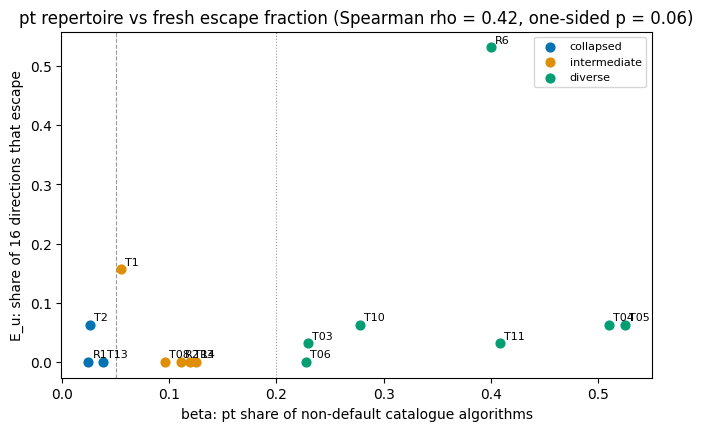

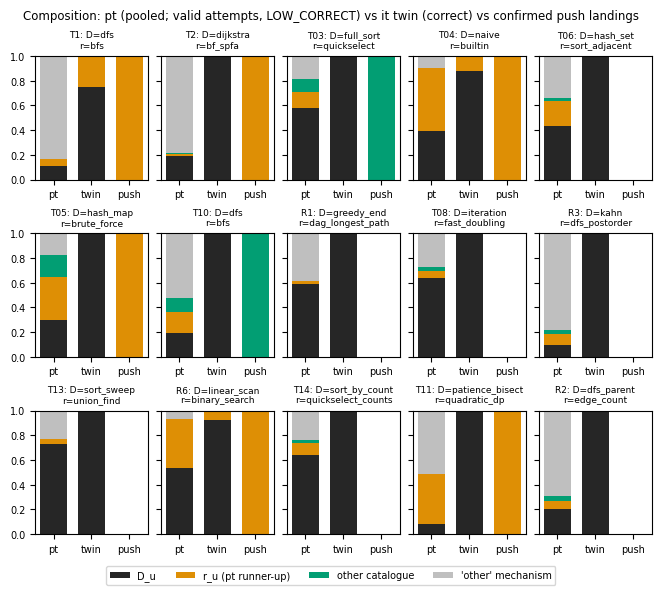

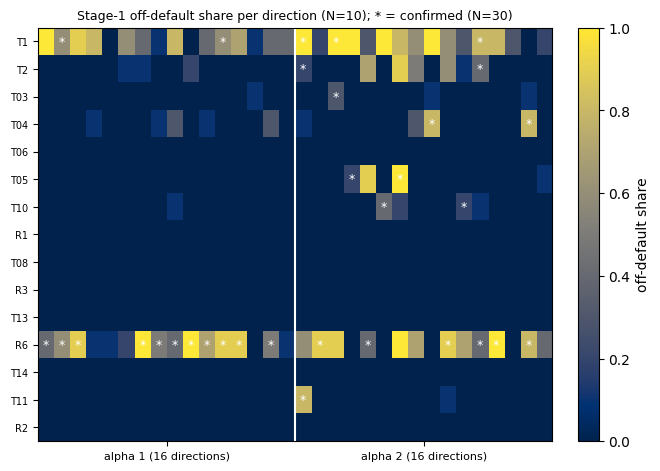

In [27]:
HOUSE = False  # figures.py: True only when the aii-data-fig-gen layout helpers are importable (not published)
PALETTE = ["#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#FBAFE4", "#949494"]


def finish(fig, name: str) -> None:
    # figures.py: house-style layout helpers, then fig.savefig(FIG_DIR / f"{name}.pdf") and (.png, dpi=200)
    plt.show()
    plt.close(fig)


def style() -> None:
    if HOUSE:
        apply_house_style()


def legend(ax, loc="best"):
    if HOUSE:
        place_legend(ax, loc=loc)
    else:
        ax.legend(loc=loc, fontsize=8)


def f1(c1, a1, esc) -> None:
    style()
    fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
    units = a1["units"]
    x = [a1["beta"][t] for t in units]
    y = [a1["E"][t] for t in units]
    cls = [c1["units"][t]["class"] for t in units]
    col = {"COLLAPSED": PALETTE[0], "INTERMEDIATE": PALETTE[1], "DIVERSE": PALETTE[2]}
    for c in ("COLLAPSED", "INTERMEDIATE", "DIVERSE"):
        xi = [a for a, k in zip(x, cls) if k == c]
        yi = [b for b, k in zip(y, cls) if k == c]
        if xi:
            ax.scatter(xi, yi, s=40, color=col[c], label=c.lower(), zorder=3)
    for t, a, b in zip(units, x, y):
        if HOUSE:
            place_point_label(ax, literal(t), (a, b))
        else:
            ax.annotate(t, (a, b), fontsize=8, xytext=(3, 3), textcoords="offset points")
    rho = a1["rho"]
    p = a1["p_one_sided_perm"]
    ax.set_title(f"pt repertoire vs fresh escape fraction (Spearman rho = {rho if rho is None else round(rho, 2)}, "
                 f"one-sided p = {p if p is None else round(p, 3)})")
    ax.set_xlabel("beta: pt share of non-default catalogue algorithms")
    ax.set_ylabel("E_u: share of 16 directions that escape")
    ax.axvline(0.05, color="0.6", lw=0.8, ls="--")
    ax.axvline(0.2, color="0.6", lw=0.8, ls=":")
    legend(ax)
    finish(fig, "fig1_beta_vs_escape")


def f2(c1, esc) -> None:
    """Per task: share of D_u, r_u, other catalogue algorithms and 'other' in the pt primary composition (LOW_CORRECT:
    valid attempts), the it twin's correct programs and the correct off-default programs of confirmed escapes."""
    style()
    tasks = list(ALL_TASKS)
    fig, axes = plt.subplots(3, 5, figsize=(6.5, 5.8), layout="constrained", sharey=True)
    cats = ["D_u", "r_u (pt runner-up)", "other catalogue", "'other' mechanism"]
    cols = ["0.15", PALETTE[1], PALETTE[2], "0.75"]
    for ax, t in zip(axes.flat, tasks):
        u = c1["units"][t]
        cat, D, r = u["catalogue"], u["D"], u["r_u"]
        src = u[u["primary_source"]]
        pt_c = src["attempt_counts"] if u["low_correct"] else src["correct_counts"]
        pt_c = {k: v for k, v in pt_c.items() if k not in ("invalid", "disputed")}
        srcs = [pt_c, u["default"]["correct_counts"],
                (esc[t].get("landing") or {}).get("composition", {}) if esc[t].get("defaulted") else {}]
        bottom = np.zeros(3)
        for ci, cname in enumerate(cats):
            vals = []
            for sdict in srcs:
                tot = sum(v for k, v in sdict.items() if k in cat or k == "other")
                if cname == "D_u":
                    x = sdict.get(D, 0)
                elif cname.startswith("r_u"):
                    x = sdict.get(r, 0) if r else 0
                elif cname == "other catalogue":
                    x = sum(v for k, v in sdict.items() if k in cat and k not in (D, r))
                else:
                    x = sdict.get("other", 0)
                vals.append(x / tot if tot else 0.0)
            ax.bar(range(3), vals, bottom=bottom, color=cols[ci], width=0.7, label=cname if t == tasks[0] else None)
            bottom += np.array(vals)
        ax.set_xticks(range(3), ["pt", "twin", "push"], fontsize=7)
        ax.set_title(f"{t}: D={D}\nr={r}", fontsize=6.5)
        ax.tick_params(axis="y", labelsize=7)
    fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="outside lower center", ncols=4, fontsize=7)
    fig.suptitle("Composition: pt (pooled; valid attempts, LOW_CORRECT) vs it twin (correct) vs confirmed push landings",
                 fontsize=8.5)
    plt.show()  # figures.py: fig.savefig(FIG_DIR / "fig2_compositions.pdf") and (.png, dpi=200)
    plt.close(fig)


def f3(c1, esc) -> None:
    style()
    tasks = [t for t in ALL_TASKS if esc[t].get("defaulted")]
    cols = [f"{s}_a{int(a)}" for a in ALPHAS for s in DIR_SEEDS]
    M = np.array([[esc[t]["per_direction"].get(c, {}).get("off_cat") or 0.0 for c in cols] for t in tasks])
    fig, ax = plt.subplots(figsize=(6.5, 4.6), layout="constrained")
    im = ax.imshow(M, aspect="auto", cmap="cividis", vmin=0, vmax=1)
    for i, t in enumerate(tasks):
        for j, c in enumerate(cols):
            if esc[t]["per_direction"].get(c, {}).get("confirmed"):
                ax.text(j, i, "*", ha="center", va="center", color="white", fontsize=9)
    ax.set_yticks(range(len(tasks)), tasks, fontsize=7)
    ax.set_xticks([7.5, 23.5], ["alpha 1 (16 directions)", "alpha 2 (16 directions)"], fontsize=8)
    ax.axvline(15.5, color="white", lw=1.5)
    ax.grid(False)
    ax.set_title("Stage-1 off-default share per direction (N=10); * = confirmed (N=30)", fontsize=9)
    cb = fig.colorbar(im, ax=ax)
    cb.set_label("off-default share")
    plt.show()  # figures.py: fig.savefig(FIG_DIR / "fig3_direction_heatmap.pdf") and (.png, dpi=200)
    plt.close(fig)


def f4(tp) -> None:
    if not tp or not tp.get("per_unit"):
        return
    style()
    units = list(tp["per_unit"])
    arms = ["twin", "T", "RND", "XT", "RP"]
    fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
    w = 0.16
    for i, a in enumerate(arms):
        vals, lo, hi = [], [], []
        for u in units:
            d = tp["per_unit"][u].get(a, {})
            s = d.get("s")
            ci = d.get("s_ci95") or [s, s]
            vals.append(s if s is not None else 0)
            lo.append(max(0.0, (s or 0) - (ci[0] if ci[0] is not None else 0)))
            hi.append(max(0.0, (ci[1] if ci[1] is not None else 0) - (s or 0)))
        ax.bar(np.arange(len(units)) + (i - 2) * w, vals, width=w, yerr=[lo, hi], capsize=2, label=a,
               color=PALETTE[i % len(PALETTE)])
    for j, u in enumerate(units):
        b = tp["per_unit"][u].get("beta")
        if b is not None:
            ax.plot([j - 2.5 * w, j + 2.5 * w], [b, b], color="0.2", ls="--", lw=1)
    ax.set_xticks(range(len(units)), units)
    ax.set_ylabel("correct catalogue off-default share")
    ax.set_title(f"pt->it transplant (lambda={tp['lambda'].get('lambda')}) vs matched controls; dashed = beta")
    legend(ax, "upper right")
    finish(fig, "fig4_transplant")


def f5(norms) -> None:
    if not norms:
        return
    style()
    pb = norms["per_block"]
    ls = [int(l) for l in pb]
    med = [pb[str(l)]["median_units"] for l in ls]
    lo = [pb[str(l)]["iqr"][0] for l in ls]
    hi = [pb[str(l)]["iqr"][1] for l in ls]
    ms = [pb[str(l)]["massive_share_median"] for l in ls]
    fig, ax = plt.subplots(figsize=(6.5, 3.6), layout="constrained")
    ax.plot(ls, med, marker="o", color=PALETTE[0], label="median ||d_ox|| / n (ban-free units)")
    ax.fill_between(ls, lo, hi, color=PALETTE[0], alpha=0.2)
    ax.axhline(4, color="0.4", ls="--", lw=1, label="random-noise breakage dose (about 4 units)")
    ax.set_xlabel("block")
    ax.set_ylabel("transplant displacement (ban-free units)")
    ax2 = ax.twinx()
    ax2.plot(ls, ms, marker="s", color=PALETTE[1], label="massive-channel share of ||d||^2")
    ax2.set_ylabel("massive share")
    ax2.set_ylim(0, 1)
    ax.set_title("pt - it displacement at task-spec positions (transplant tasks)")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower left")
    plt.show()  # figures.py: fig.savefig(FIG_DIR / "fig5_transplant_norms.pdf") and (.png, dpi=200)
    plt.close(fig)


f1(c1, a1, esc)
f2(c1, esc)
f3(c1, esc)

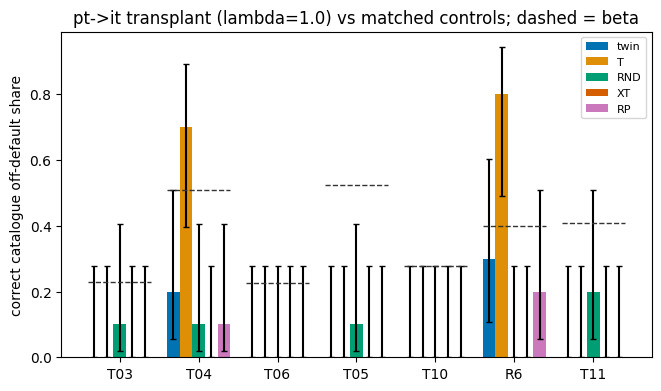

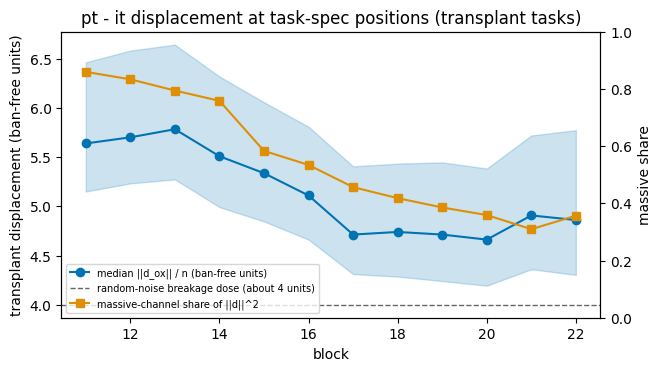

In [28]:
f4(tp)
f5(tp["norms"])

### Inside the model: the realised transplant displacement

Every stored T program carries `realised_disp`, measured during its prefill: the mean over task-spec positions of
‖h_T − h_twin‖ at each block from 11 to 33 (`engine.prefill_single`). Blocks 11–22 are written by the transplant;
blocks 23–33 only show how the written difference propagates. Below are the median curves per task over the
selected prompts. Collapsed controls are dashed and the shaded area is the band.

The written difference has about the same size on every task, moved or not, so size alone does not explain why
only T04 and R6 move. The full run makes a related point about the controls: RND and XT match T's non-massive norm
and copy its massive-channel move, yet they break most programs, so content rather than size separates T from them.

After the plot come two transplanted programs that left the default: on T04 the twin wrote a naive search on the
same slot, and on R6 a linear scan.

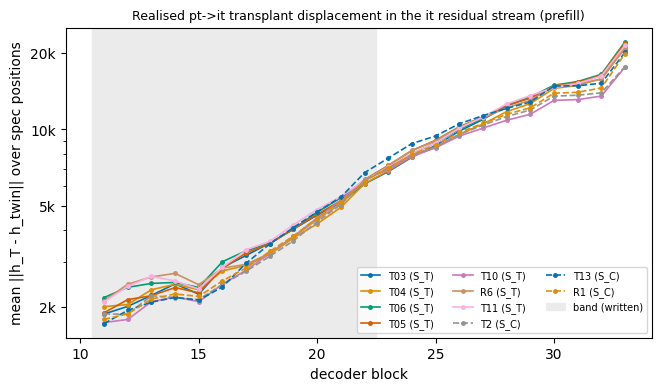

--- T04 slot (W1, 0): twin wrote naive (pass=True); transplant T wrote builtin (pass=True) ---
def solve(haystack, needle):
    """
    Finds the index of the first occurrence of needle in haystack.

    Args:
        haystack: The string to search within.
        needle: The string to search for.

    Returns:
        The index of the first occurrence of needle in haystack, or -1 if not found.
    """
    try:
        return haystack.index(needle)
    except ValueError:
        return -1

--- R6 slot (W3, 0): twin wrote linear_scan (pass=True); transplant T wrote binary_search (pass=True) ---
def solve(nums, target):
    """
    Finds the first and last index of a target value in a sorted list.

    Args:
        nums: A list of integers sorted in non-decreasing order.
        target: The integer to search for.

    Returns:
        A list [first, last] holding the first and the last index at which target occurs in nums,
        or [-1, -1] if target does not occur.
    """
    first 

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
for i, u in enumerate(tp["S_T"] + tp["S_C"]):
    S = np.array([r["realised_disp"]["S_by_block"] for r in rows("transplant", u, "T") if r.get("realised_disp")])
    if len(S):
        ax.plot(CAPTURE_BLOCKS, np.median(S, 0), marker="o", ms=2.5, lw=1.2, color=PALETTE[i % len(PALETTE)],
                ls="-" if u in tp["S_T"] else "--", label=f"{u} ({'S_T' if u in tp['S_T'] else 'S_C'})")
ax.axvspan(BAND[0] - 0.5, BAND[-1] + 0.5, color="0.92", zorder=0, label="band (written)")
ax.set_yscale("log")
ax.set_yticks([2e3, 5e3, 1e4, 2e4], ["2k", "5k", "10k", "20k"])
ax.set_xlabel("decoder block")
ax.set_ylabel("mean ||h_T - h_twin|| over spec positions")
ax.set_title("Realised pt->it transplant displacement in the it residual stream (prefill)", fontsize=9)
ax.legend(fontsize=7, ncols=3, loc="lower right")
plt.show()
plt.close(fig)

for u in ("T04", "R6"):
    D, r_u = c1["units"][u]["D"], c1["units"][u]["r_u"]
    moved = [r for r in rows("transplant", u, "T") if r["passed"] and r["label"] == r_u
             and labels()[f"twin|{u}|{r['template']}|twin|{r['slot']}"]["label"] == D]
    if moved:
        r = moved[0]
        tw = labels()[f"twin|{u}|{r['template']}|twin|{r['slot']}"]
        print(f"--- {u} slot ({r['template']}, {r['slot']}): twin wrote {tw['label']} (pass={tw['passed']}); "
              f"transplant T wrote {r['label']} (pass={r['passed']}) ---")
        print(r["code"][:700])
print(f"runtime since the data was loaded: {time.time() - t0_notebook:.1f} s")

## Summary and how to run the full experiment

**Results.** The notebook re-runs the frozen analysis on the stored outputs. With the original 200,000 permutations
and 10,000 bootstrap draws it reproduces the full run's pre-registered tests:
- **E-A2 passes.** In 5 of 7 events the pt runner-up is where the nudged programs land (p = 0.025), and the
  pt-composition forecast beats iteration 4's association forecast by about 1.5 nats per event.
- **E-A1 is inconclusive.** ρ(β, E) = 0.42 with p = 0.06 at n = 15. The it model's own twin modal share
  (ρ = 0.67) and the novelty instruction (ρ = 0.64) track movability better than β.

**The transplant.** Even at N = 10 per arm, the 100 stored programs show the same picture as the full run:
- the pt task-spec states move T04 (naive → builtin) and R6 (linear scan → binary search), both onto the pt
  runner-up;
- the other base-diverse tasks stay at the it default;
- every transplanted program stays valid, while the matched random (RND) and cross-task (XT) displacements break
  most programs;
- the collapsed controls stay inert.

The two moved tasks are those whose it twin already writes the runner-up 8–12% of the time. The transplant amplifies
an existing minority mode; it does not install an absent one.

**Full pipeline.** Clone the artifact folder and install its pinned environment
(`uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml`). Accept the Gemma
licence and export `HF_TOKEN` and `OPENROUTER_API_KEY`, then run `.venv/bin/python method.py` (about 2.5 GPU-hours on
one 23 GB NVIDIA L4). On the stored samples, `method.py --from analysis` recomputes every result on CPU.